## Introduction

In this post, we'll take a look at historical return correlations between asset classes, including rolling correlations and how those correlations have changed over time. We'll also build a "total correlation" metric, and a trading strategy that uses correlation as a market timing signal.

 ## Python Imports

In [1]:
# Standard Library
import os
import sys
import warnings

from IPython.display import display, Markdown
from itertools import combinations, count
from pathlib import Path

# Data Handling
import numpy as np
import pandas as pd

# Suppress warnings
warnings.filterwarnings("ignore")

# Pandas display options
pd.set_option("display.float_format", lambda x: f"%.2f" % x)

In [2]:
# Add the source subdirectory to the system path to allow import config from settings.py
current_directory = Path(os.getcwd())
BASE_DIR = current_directory.parent.parent.parent
src_directory = BASE_DIR / "src"
sys.path.append(str(src_directory)) if str(src_directory) not in sys.path else None

# Import settings.py
from settings import config

# Add other configured directories
CONTENT_DIR = config("CONTENT_DIR")
POSTS_DIR = config("POSTS_DIR")
PAGES_DIR = config("PAGES_DIR")
PUBLIC_DIR = config("PUBLIC_DIR")
SOURCE_DIR = config("SOURCE_DIR")
DATA_DIR = config("DATA_DIR")
DATA_MANUAL_DIR = config("DATA_MANUAL_DIR")

## Python Functions

Here are the functions needed for this project:

* [load_data](/posts/reusable-extensible-python-functions-financial-data-analysis/#load_data): Load data from a CSV, Excel, or Pickle file into a pandas DataFrame.
* [plot_histogram](/posts/reusable-extensible-python-functions-financial-data-analysis/#plot_histogram): Plot the histogram of a data set from a DataFrame.
* [plot_scatter](/posts/reusable-extensible-python-functions-financial-data-analysis/#plot_scatter): Plot the data from a DataFrame for a specified date range and columns.
* [plot_time_series](/posts/reusable-extensible-python-functions-financial-data-analysis/#plot_time_series): Plot the timeseries data from a DataFrame for a specified date range and columns.
* [run_linear_regression](/posts/reusable-extensible-python-functions-financial-data-analysis/#run_linear_regression): Run a linear regression using statsmodels OLS and return the results.
* [summary_stats](/posts/reusable-extensible-python-functions-financial-data-analysis/#summary_stats): Generate summary statistics for a series of returns.
* [yf_pull_data](/posts/reusable-extensible-python-functions-financial-data-analysis/#yf_pull_data): Download daily price data from Yahoo Finance and export it.

In [3]:
from load_data import load_data
from plot_heatmap import plot_heatmap
from plot_histogram import plot_histogram
from plot_scatter import plot_scatter
from plot_time_series import plot_time_series
from summary_stats import summary_stats
from yf_pull_data import yf_pull_data

## Data Overview

For this exercise, we will (mostly) use ETFs as a proxy for asset classes and will use the following:

* Large Cap US Stocks / S&P 500 -- IVV (iShares S&P 500 ETF)
* Mid Cap US Stocks / S&P MidCap 400 -- IJH (iShares S&P MidCap 400 ETF)
* Small Cap US Stocks / S&P SmallCap 600 -- IJR (iShares S&P SmallCap 600 ETF)
* US Tech Stocks / Nasdaq 100 -- QQQ (Invesco QQQ Trust, Series 1)
* US Value Stocks -- IWD (iShares Russell 1000 Value ETF)
* US Growth Stocks -- IWF (iShares Russell 1000 Growth ETF)
* International Developed Market Stocks -- EFA (iShares MSCI EAFE ETF)
* Emerging Market Stocks -- EEM (iShares MSCI Emerging Markets ETF)
* European Stocks -- IEV (iShares S&P Europe 350 ETF)
* Short-Term US Treasuries -- SHY (iShares 1-3 Year Treasury Bond ETF)
* Medium-Term US Treasuries -- IEF (iShares 7-10 Year Treasury Bond ETF)
* Long-Term US Treasuries -- TLT (iShares 20+ Year Treasury Bond ETF)
* Aggregate Bonds -- AGG (iShares Core U.S. Aggregate Bond ETF)
* Gold -- GLD (SPDR Gold Shares)
* Commodities -- GSG (iShares S&P GSCI Commodity-Indexed Trust)
* Real Estate -- IYR (iShares U.S. Real Estate ETF)
* Bitcoin -- BTC-USD (Bitcoin USD)
* Ethereum -- ETH-USD (Ethereum USD)

For all of these, we will use the adjusted closing price, which accounts for dividends and stock splits.

### Acquire & Plot Data

We'll now pull the data for all the ETFs and cryptocurrencies listed above.

In [4]:
figure_number = count(1)
table_number = count(1)

# Create list of tickers to pull data for
us_equity_tickers = ["IVV", "IJH", "IJR", "QQQ", "IWB", "IWD", "IWF", "IWM"]
intl_equity_tickers = ["EFA", "EEM", "IEV"]
equity_tickers = us_equity_tickers + intl_equity_tickers
bond_tickers = ["SHY", "IEF", "TLT", "AGG"]
commodity_tickers = ["GLD", "GSG"]
real_estate_tickers = ["IYR"]
cryptoasset_tickers = ["BTC-USD", "ETH-USD"]
etf_tickers = (
    us_equity_tickers
    + intl_equity_tickers
    + bond_tickers
    + commodity_tickers
    + real_estate_tickers
)

tickers_dict = {
    "IVV": "Large Cap US Stocks / S&P 500 -- IVV (iShares S&P 500 ETF)",
    "IJH": "Mid Cap US Stocks / S&P MidCap 400 -- IJH (iShares S&P MidCap 400 ETF)",
    "IJR": "Small Cap US Stocks / S&P SmallCap 600 -- IJR (iShares S&P SmallCap 600 ETF)",
    "QQQ": "US Tech Stocks / Nasdaq 100 -- QQQ (Invesco QQQ Trust, Series 1)",
    "IWB": "Large & Mid Cap US Stocks -- IWB (iShares Russell 1000 ETF)",
    "IWM": "Small Cap US Stocks -- IWM (iShares Russell 2000 ETF)",
    "IWD": "Large & Mid Cap US Value Stocks -- IWD (iShares Russell 1000 Value ETF)",
    "IWF": "Large & Mid Cap US Growth Stocks -- IWF (iShares Russell 1000 Growth ETF)",
    "EFA": "International Developed Market Stocks -- EFA (iShares MSCI EAFE ETF)",
    "EEM": "Emerging Market Stocks -- EEM (iShares MSCI Emerging Markets ETF)",
    "IEV": "European Stocks -- IEV (iShares S&P Europe 350 ETF)",
    "SHY": "Short-Term US Treasuries -- SHY (iShares 1-3 Year Treasury Bond ETF)",
    "IEF": "Medium-Term US Treasuries -- IEF (iShares 7-10 Year Treasury Bond ETF)",
    "TLT": "Long-Term US Treasuries -- TLT (iShares 20+ Year Treasury Bond ETF)",
    "AGG": "Aggregate Bonds -- AGG (iShares Core U.S. Aggregate Bond ETF)",
    "GLD": "Gold -- GLD (SPDR Gold Shares)",
    "GSG": "Commodities -- GSG (iShares S&P GSCI Commodity-Indexed Trust)",
    "IYR": "Real Estate -- IYR (iShares U.S. Real Estate ETF)",
    "BTC-USD": "Bitcoin -- BTC-USD (Bitcoin USD)",
    "ETH-USD": "Ethereum -- ETH-USD (Ethereum USD)",
}

In [5]:
for ticker in etf_tickers:
    yf_pull_data(
        base_directory=DATA_DIR,
        ticker=ticker,
        adjusted=False,
        source="Yahoo_Finance",
        asset_class="Exchange_Traded_Funds",
        excel_export=True,
        pickle_export=True,
        output_confirmation=False,
    )

for ticker in cryptoasset_tickers:
    yf_pull_data(
        base_directory=DATA_DIR,
        ticker=ticker,
        adjusted=False,
        source="Yahoo_Finance",
        asset_class="Cryptocurrencies",
        excel_export=True,
        pickle_export=True,
        output_confirmation=False,
    )

### Load & Filter Data

We'll then peform the following:
* Load data
* Rename columns to include the ticker (e.g. "QQQ_Close", "QQQ_Adj_Close", etc.)
* Drop all columns except for "Adj Close"
* Calculate the daily returns
* Combine the data into a single DataFrame
* Check the inception date for each of thge funds

In [6]:
fund_data = pd.DataFrame()

for ticker in etf_tickers:
    data = load_data(
        base_directory=DATA_DIR,
        ticker=ticker,
        source="Yahoo_Finance",
        asset_class="Exchange_Traded_Funds",
        timeframe="Daily",
        file_format="pickle",
    )

    # Rename columns to "QQQ_Close", etc.
    data = data.rename(
        columns={
            "Adj Close": f"{ticker}_Adj_Close",
            "Close": f"{ticker}_Close",
            "High": f"{ticker}_High",
            "Low": f"{ticker}_Low",
            "Open": f"{ticker}_Open",
            "Volume": f"{ticker}_Volume",
        }
    )

    # Drop all columns except for the adjusted close price and date index
    data = data[[f"{ticker}_Adj_Close"]]

    # Calculate daily returns and add as new column
    data[f"{ticker}_Daily_Return"] = data[f"{ticker}_Adj_Close"].pct_change()

    # Concatenate the data for this ticker with the main fund_data DataFrame
    fund_data = pd.concat([fund_data, data], axis=1)

for ticker in cryptoasset_tickers:
    data = load_data(
        base_directory=DATA_DIR,
        ticker=ticker,
        source="Yahoo_Finance",
        asset_class="Cryptocurrencies",
        timeframe="Daily",
        file_format="pickle",
    )

    # Rename columns to "BTC-USD_Close", etc.
    data = data.rename(
        columns={
            "Adj Close": f"{ticker}_Adj_Close",
            "Close": f"{ticker}_Close",
            "High": f"{ticker}_High",
            "Low": f"{ticker}_Low",
            "Open": f"{ticker}_Open",
            "Volume": f"{ticker}_Volume",
        }
    )

    # Drop all columns except for the adjusted close price and date index
    data = data[[f"{ticker}_Adj_Close"]]

    # Calculate daily returns and add as new column
    data[f"{ticker}_Daily_Return"] = data[f"{ticker}_Adj_Close"].pct_change()

    # Concatenate the data for this ticker with the main fund_data DataFrame
    fund_data = pd.concat([fund_data, data], axis=1)

display(Markdown(f"Table {next(table_number)}: Fund Data"))
display(fund_data)

Table 1: Fund Data

,IVV_Adj_Close,IVV_Daily_Return,IJH_Adj_Close,IJH_Daily_Return,IJR_Adj_Close,IJR_Daily_Return,QQQ_Adj_Close,QQQ_Daily_Return,IWB_Adj_Close,IWB_Daily_Return,...,GLD_Adj_Close,GLD_Daily_Return,GSG_Adj_Close,GSG_Daily_Return,IYR_Adj_Close,IYR_Daily_Return,BTC-USD_Adj_Close,BTC-USD_Daily_Return,ETH-USD_Adj_Close,ETH-USD_Daily_Return
Date,,,,,,,,,,,,,,,,,,,,,
1999-03-10,NaN,NaN,NaN,NaN,NaN,NaN,42.98,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-03-11,NaN,NaN,NaN,NaN,NaN,NaN,43.19,0.00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-03-12,NaN,NaN,NaN,NaN,NaN,NaN,42.14,-0.02,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-03-15,NaN,NaN,NaN,NaN,NaN,NaN,43.35,0.03,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-03-16,NaN,NaN,NaN,NaN,NaN,NaN,43.72,0.01,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,80790.84,-0.00,2355.95,-0.01
2026-10-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,80024.01,-0.01,2326.92,-0.01
2026-10-26,768.69,0.01,72.91,0.01,138.93,0.01,712.20,0.01,418.06,0.01,...,367.82,0.00,37.31,-0.01,98.83,0.00,80006.66,-0.00,2320.28,-0.00


In [7]:
for ticker in tickers_dict.keys():
    print(f"First date for {ticker}: {fund_data[f'{ticker}_Daily_Return'].first_valid_index()}")

First date for IVV: 2000-05-22 00:00:00
First date for IJH: 2000-05-30 00:00:00
First date for IJR: 2000-05-30 00:00:00
First date for QQQ: 1999-03-11 00:00:00
First date for IWB: 2000-05-22 00:00:00
First date for IWM: 2000-05-30 00:00:00
First date for IWD: 2000-05-30 00:00:00
First date for IWF: 2000-05-30 00:00:00
First date for EFA: 2001-08-28 00:00:00
First date for EEM: 2003-04-15 00:00:00
First date for IEV: 2000-07-31 00:00:00
First date for SHY: 2002-07-31 00:00:00
First date for IEF: 2002-07-31 00:00:00
First date for TLT: 2002-07-31 00:00:00
First date for AGG: 2003-09-30 00:00:00
First date for GLD: 2004-11-19 00:00:00
First date for GSG: 2006-07-24 00:00:00
First date for IYR: 2000-06-20 00:00:00
First date for BTC-USD: 2014-09-18 00:00:00
First date for ETH-USD: 2017-11-10 00:00:00


### Plot Data

We'll then plot the time series of the adjusted close prices for each of the assets.

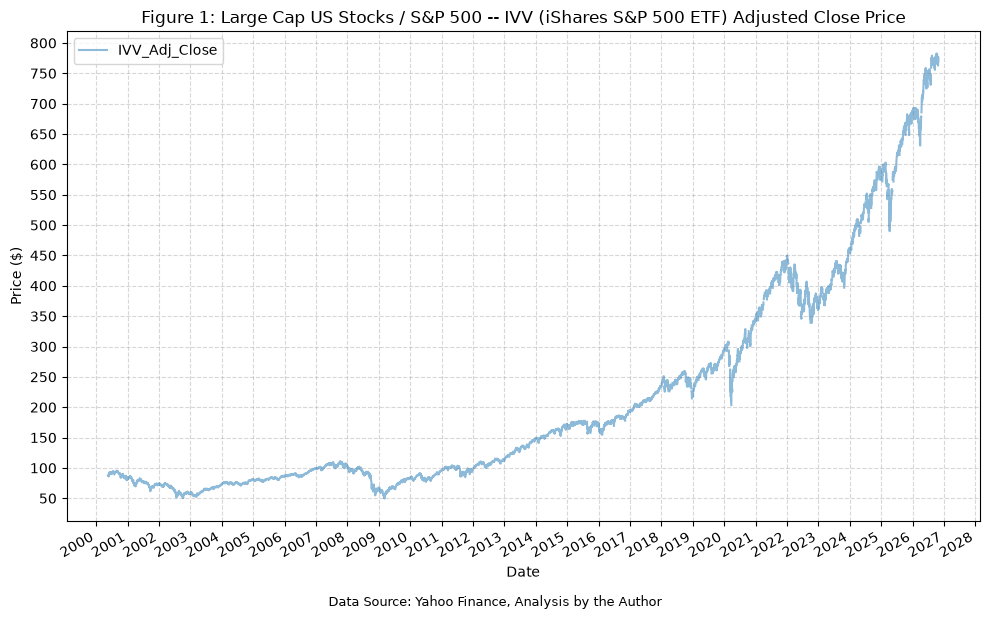

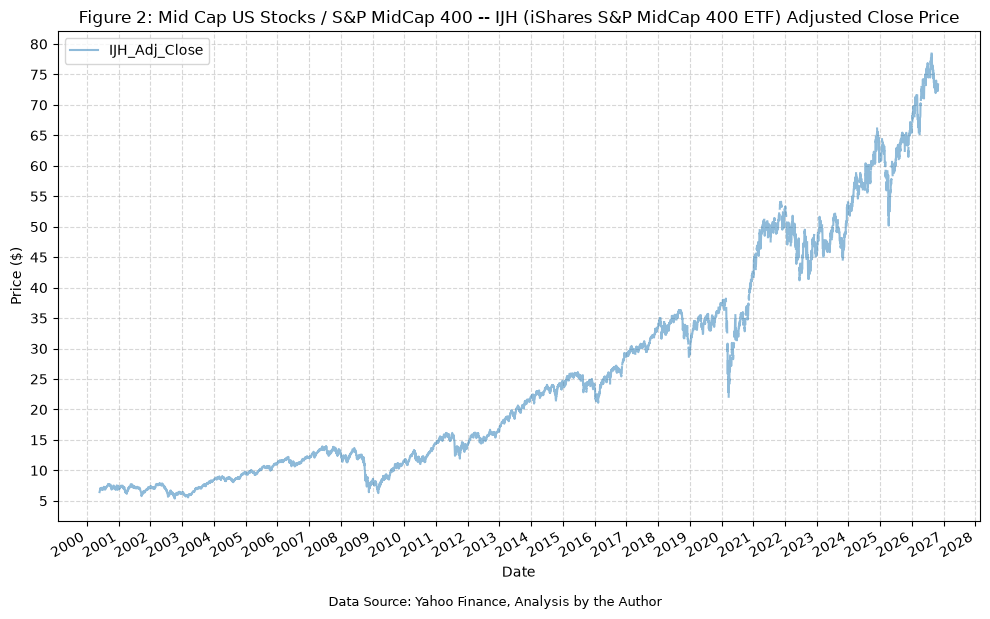

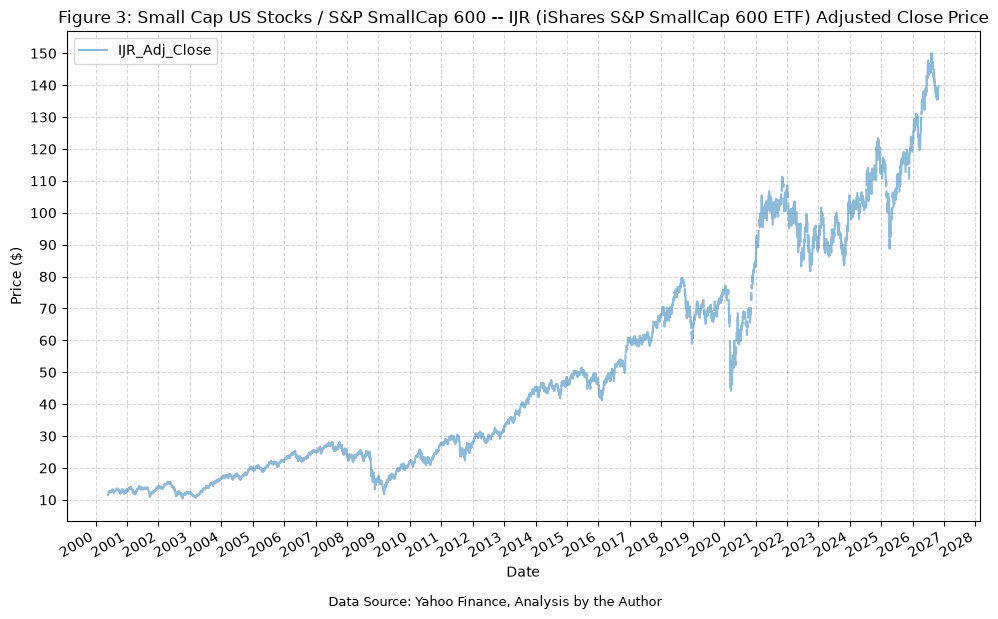

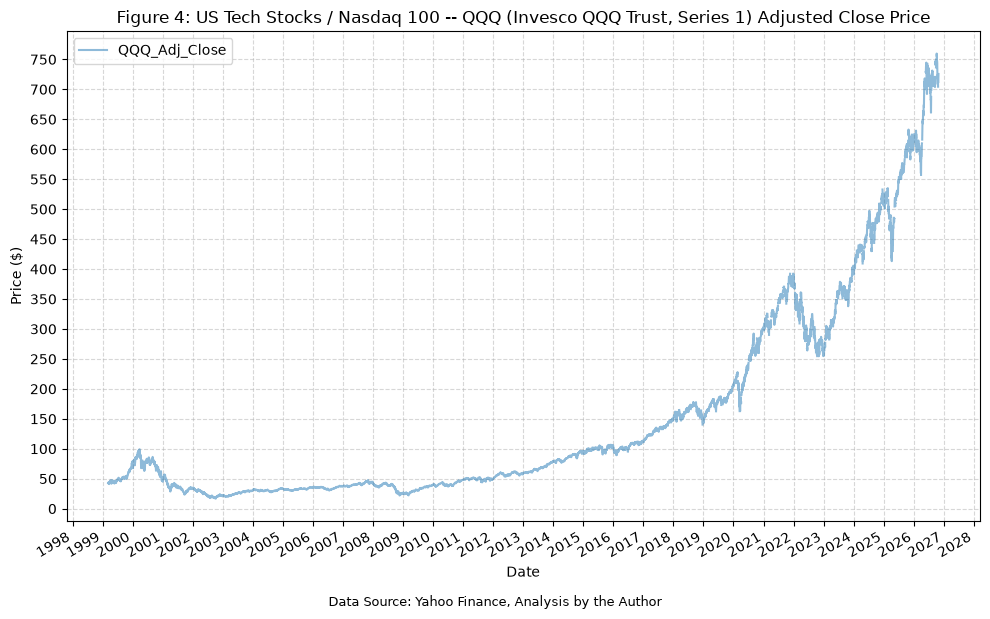

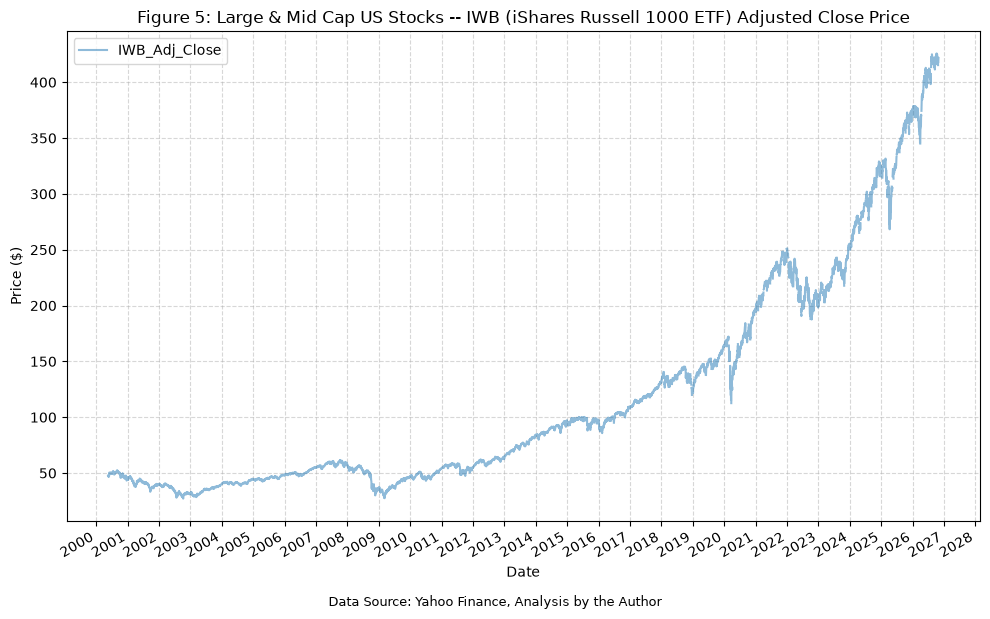

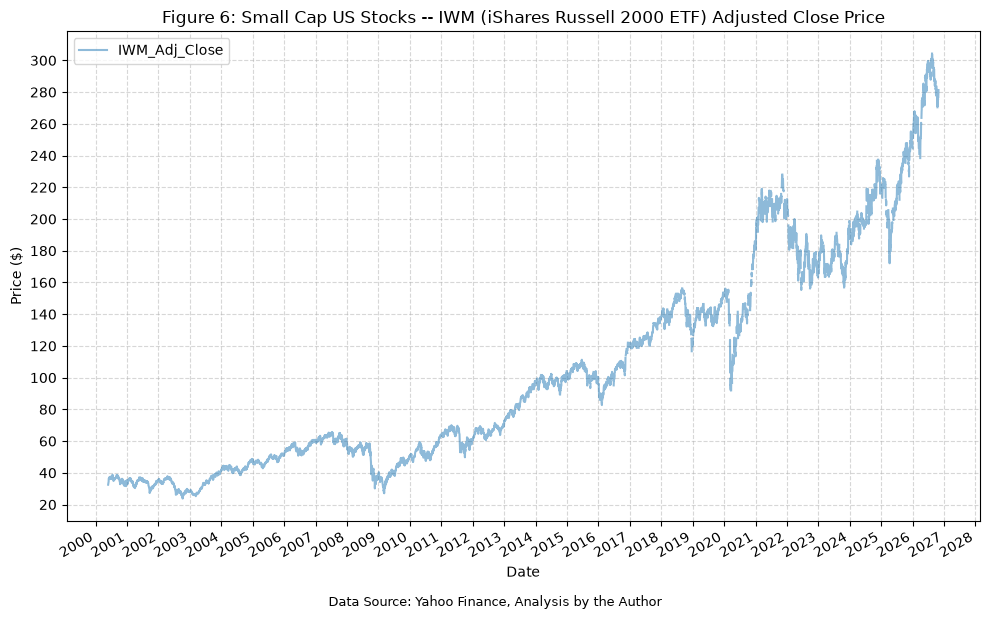

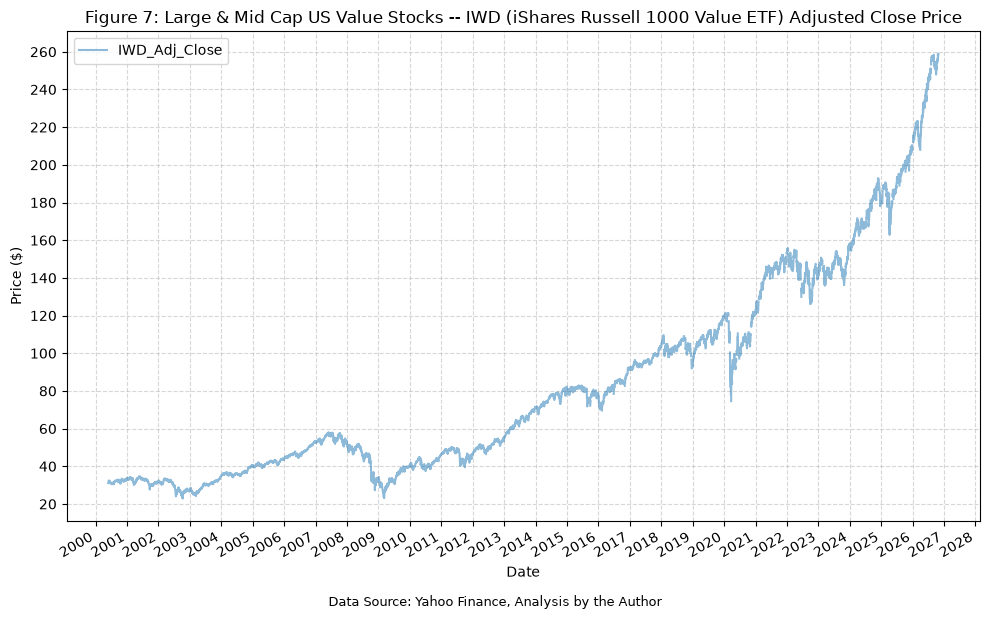

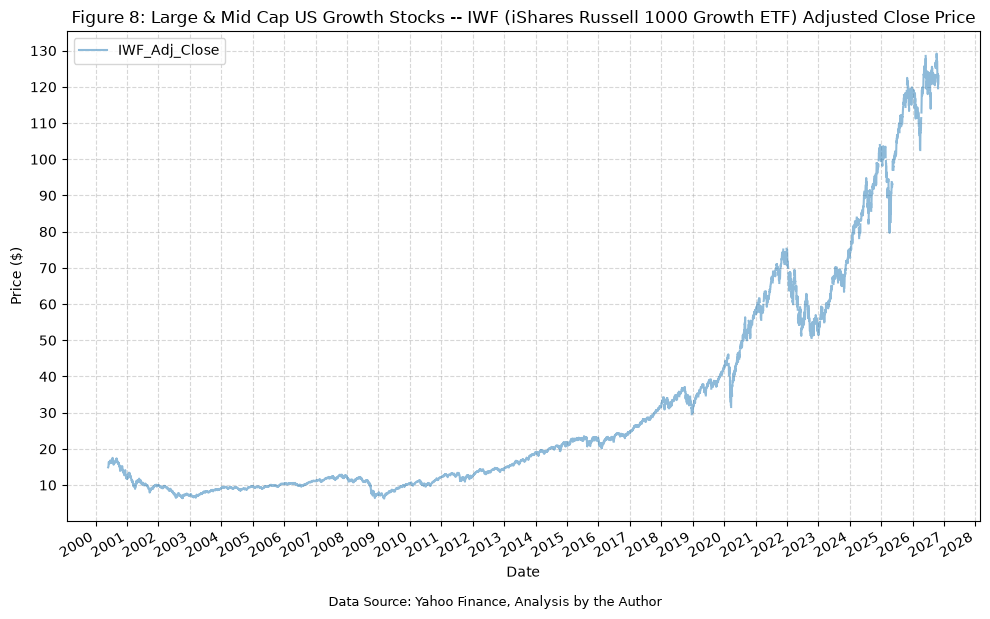

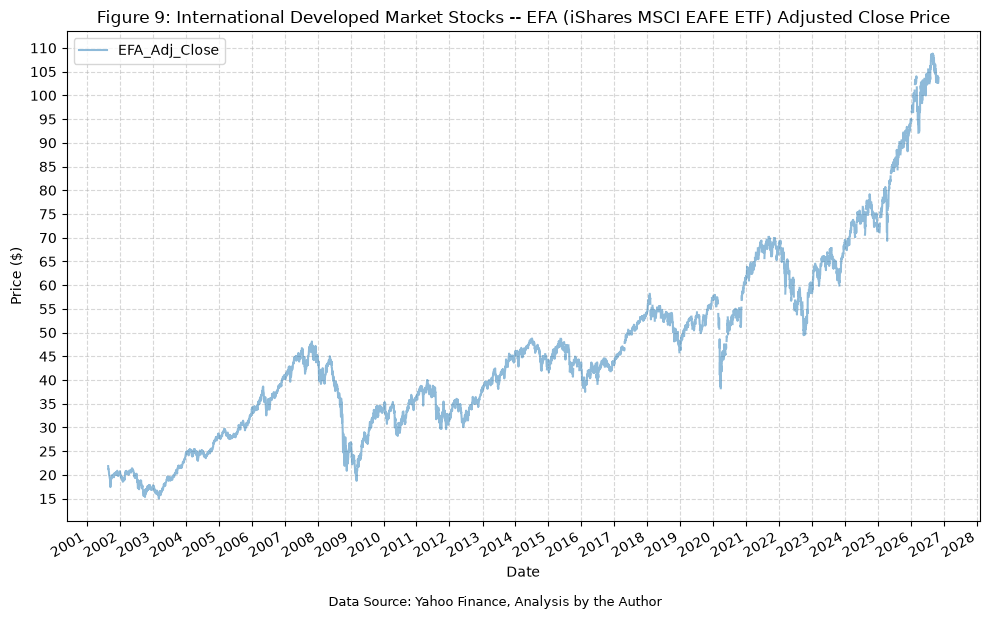

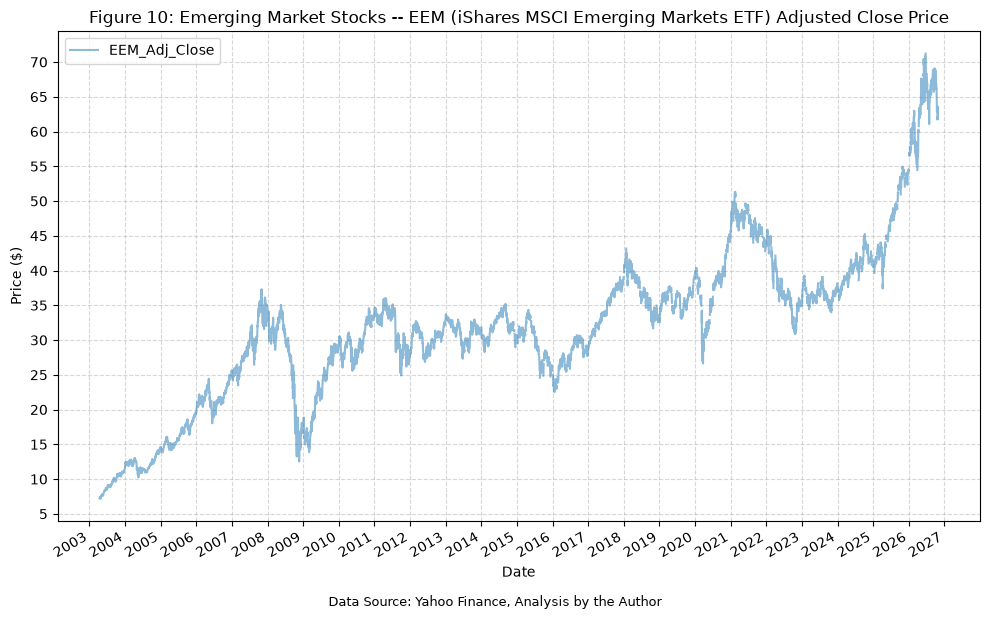

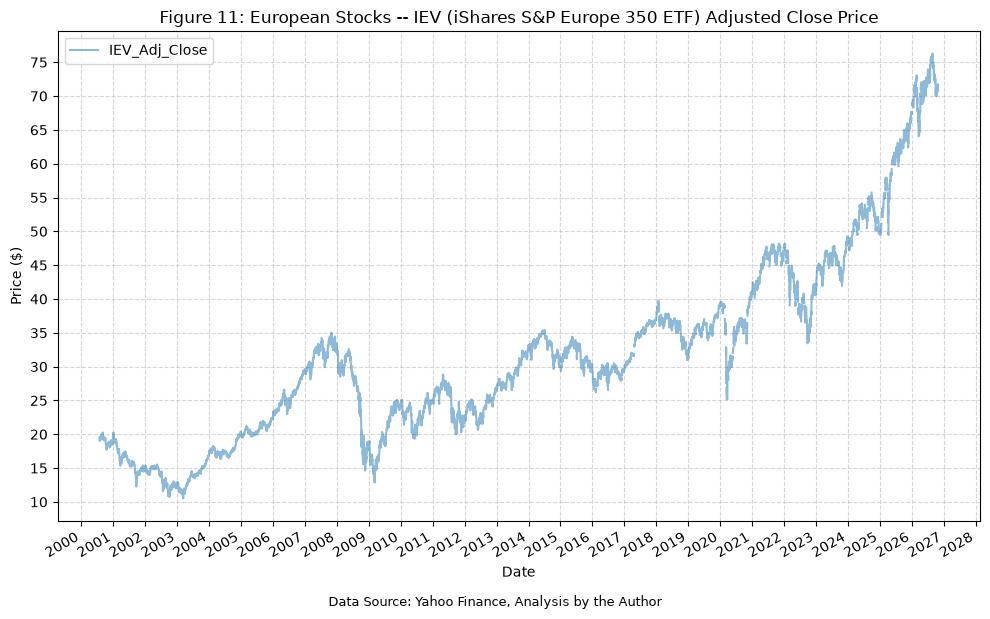

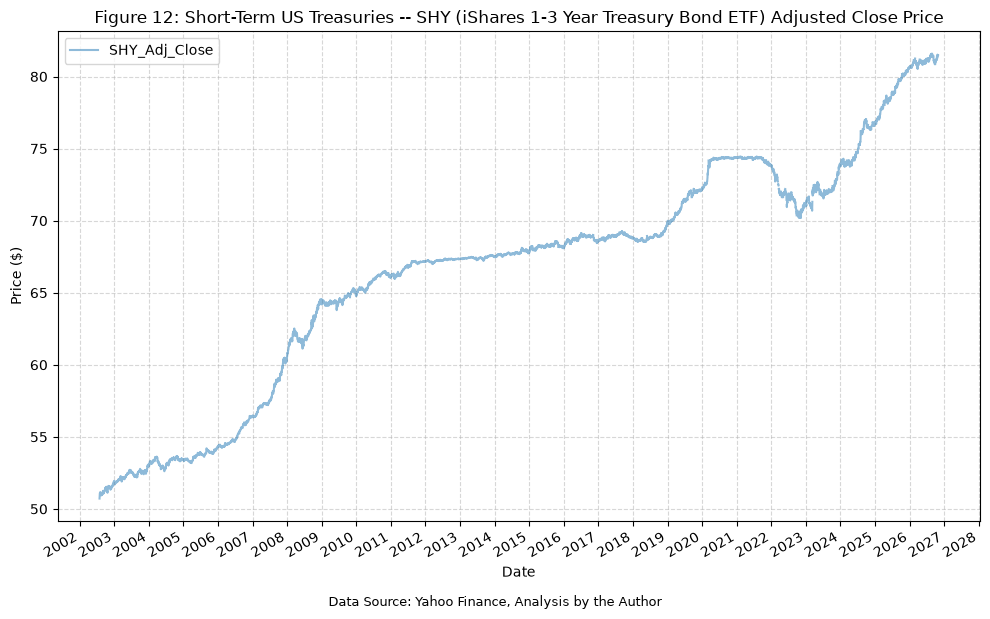

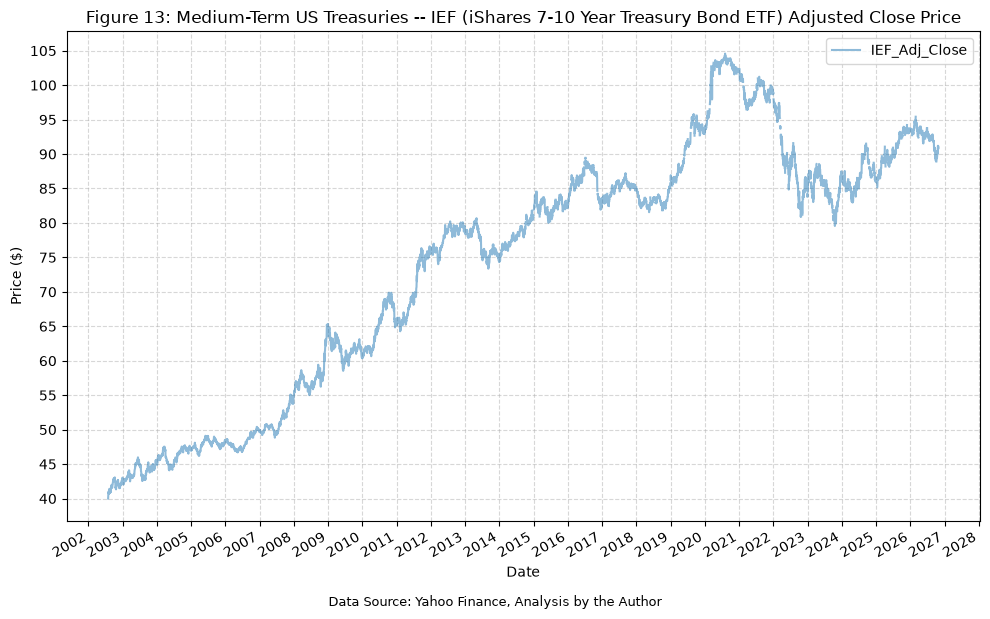

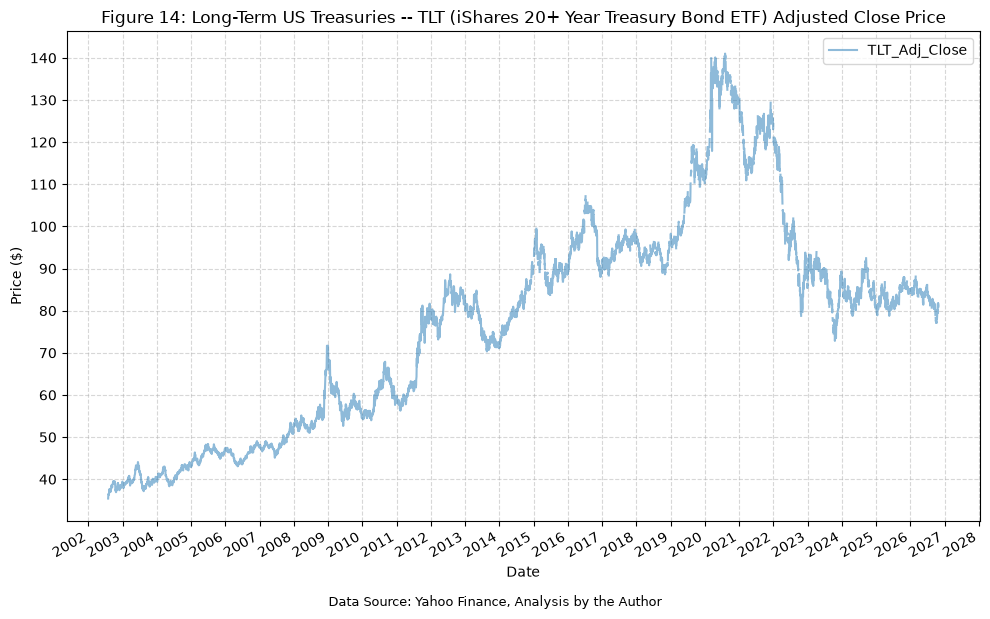

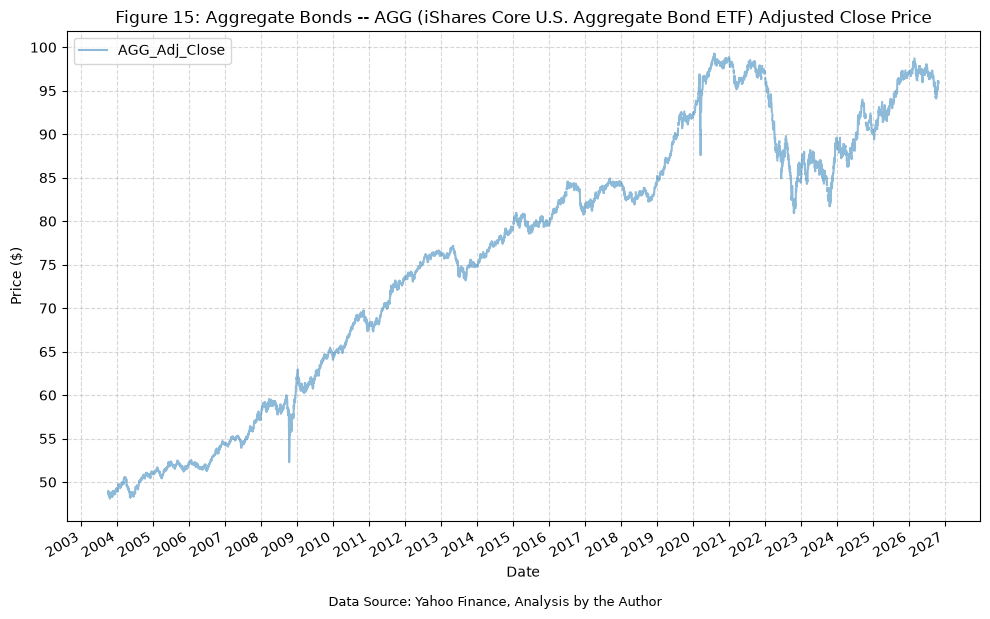

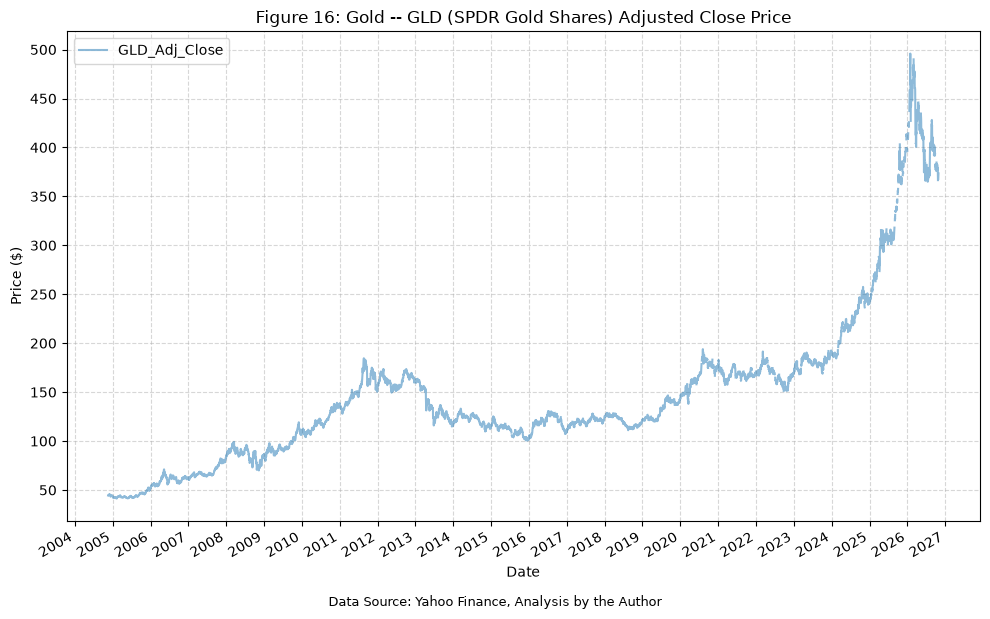

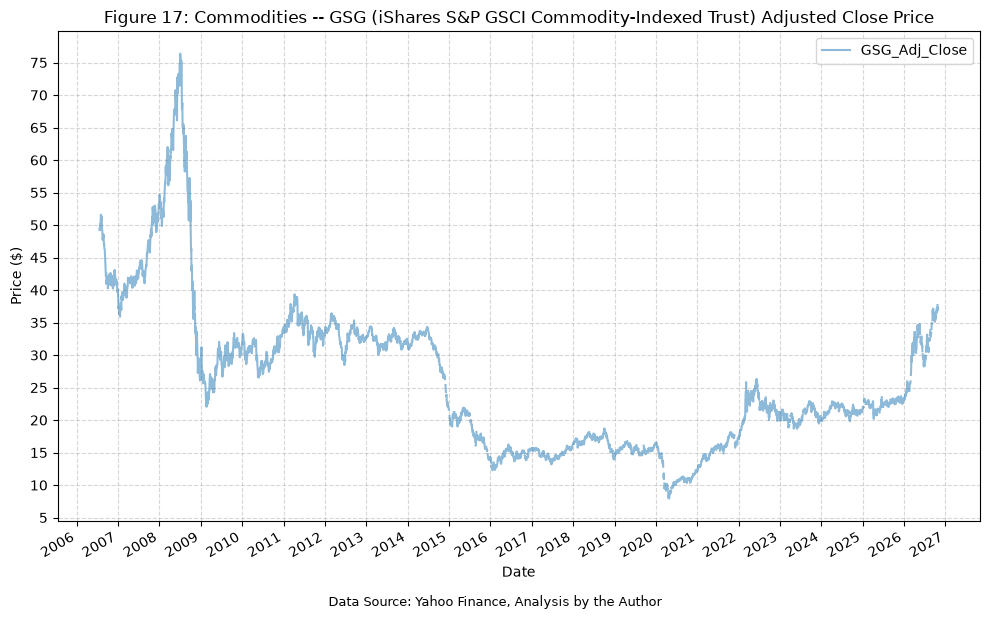

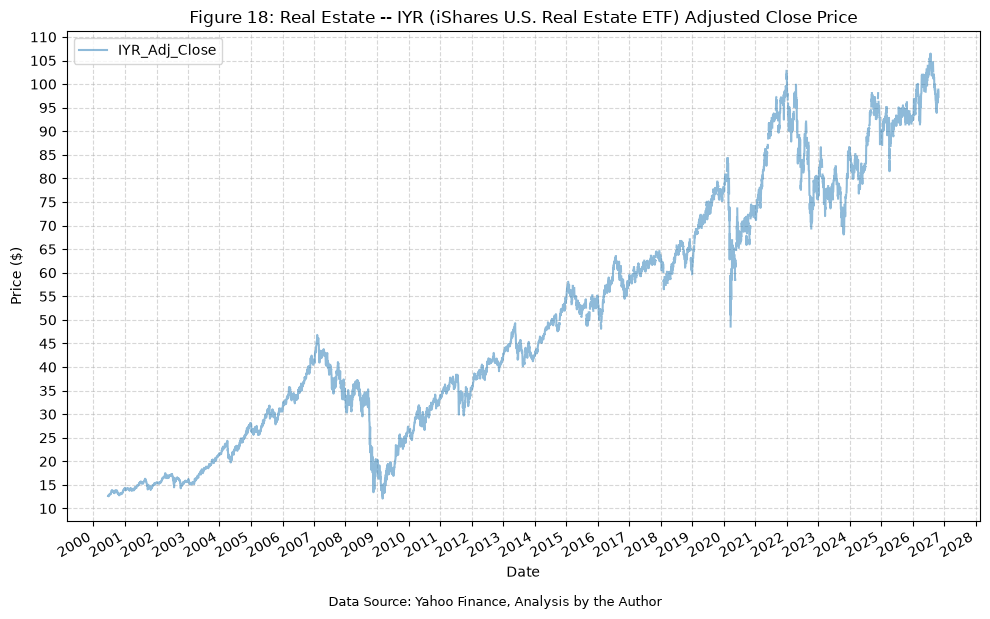

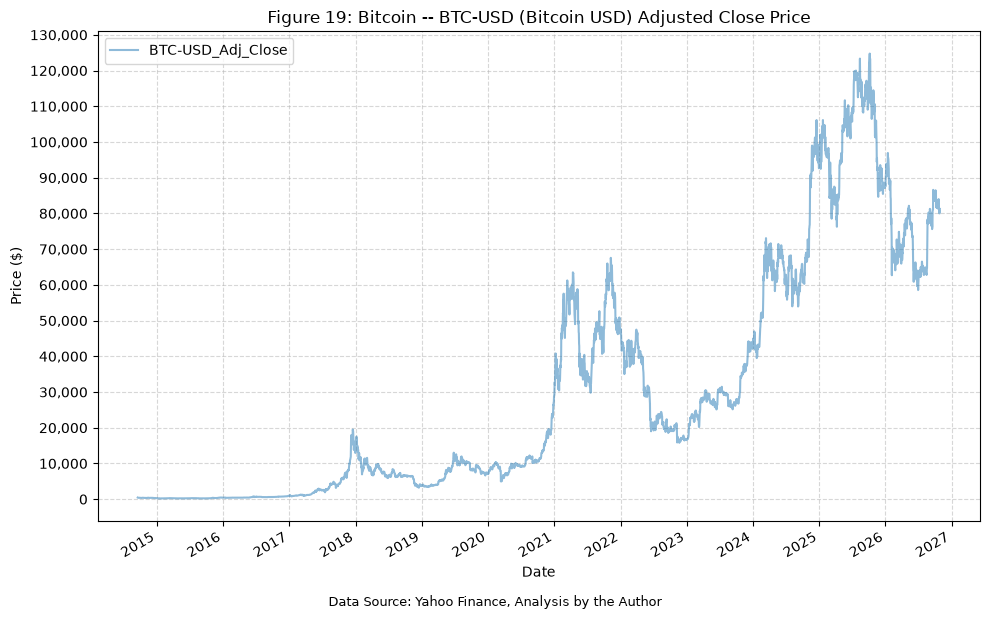

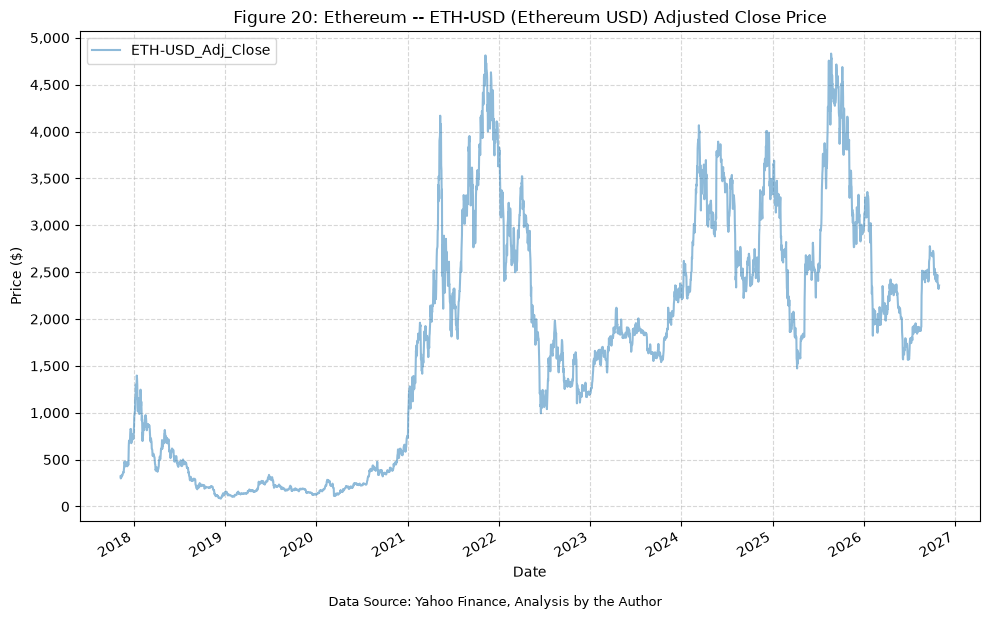

In [8]:
# Combine the etf_tickers and cryptoasset_tickers lists into a single list of all tickers
all_tickers = etf_tickers + cryptoasset_tickers

for ticker in tickers_dict.keys():
    plot_time_series(
        df=fund_data,
        plot_start_date=None,
        plot_end_date=None,
        plot_columns=[f"{ticker}_Adj_Close"],
        title=f"Figure {next(figure_number)}: {tickers_dict[ticker]} Adjusted Close Price",
        x_label="Date",
        x_format="Year",
        x_tick_spacing=1,
        x_tick_start=None,
        x_tick_rotation=30,
        y_label="Price ($)",
        y_format="Decimal",
        y_format_decimal_places="Auto",
        y_tick_spacing="Auto",
        y_tick_rotation=0,
        caption=f"Data Source: Yahoo Finance, Analysis by the Author",
    )

## Calculate Correlations

Next, we'll calculate the correlation matrix of the daily returns for all of the assets and plot it as a heatmap. We'll do this first without the BTC and ETH data (due to the limited history), and then with the BTC and ETH data.

In [9]:
# Drop the adjusted close price columns, leaving only the daily return columns
daily_return_columns = [f"{ticker}_Daily_Return" for ticker in tickers_dict.keys()]
fund_data_daily_returns_all = fund_data[daily_return_columns]

# Drop the BTC and ETH daily return columns due to the limited history
fund_data_daily_returns_no_crypto = fund_data_daily_returns_all.drop(columns=["BTC-USD_Daily_Return", "ETH-USD_Daily_Return"])

# Print the shape of the fund_data_daily_returns_no_crypto DataFrame to confirm that the rows with missing data have been dropped
print(f"Shape of fund_data_daily_returns_no_crypto: {fund_data_daily_returns_no_crypto.shape}")
print(f"Rows to drop due to missing data: {fund_data_daily_returns_no_crypto.dropna().shape}")

# Drop the NaN values
fund_data_daily_returns_no_crypto = fund_data_daily_returns_no_crypto.dropna()

# Calculate the correlation matrix of the daily returns
correlation_matrix_no_crypto = fund_data_daily_returns_no_crypto.corr()

display(Markdown(f"Table {next(table_number)}: Correlation Matrix of Daily Returns (Excluding BTC and ETH)"))
display(correlation_matrix_no_crypto)

Shape of fund_data_daily_returns_no_crypto: (8331, 18)
Rows to drop due to missing data: (5099, 18)


Table 2: Correlation Matrix of Daily Returns (Excluding BTC and ETH)

,IVV_Daily_Return,IJH_Daily_Return,IJR_Daily_Return,QQQ_Daily_Return,IWB_Daily_Return,IWM_Daily_Return,IWD_Daily_Return,IWF_Daily_Return,EFA_Daily_Return,EEM_Daily_Return,IEV_Daily_Return,SHY_Daily_Return,IEF_Daily_Return,TLT_Daily_Return,AGG_Daily_Return,GLD_Daily_Return,GSG_Daily_Return,IYR_Daily_Return
IVV_Daily_Return,1.00,0.93,0.88,0.92,1.00,0.90,0.96,0.96,0.88,0.82,0.86,-0.23,-0.30,-0.31,-0.01,0.07,0.37,0.76
IJH_Daily_Return,0.93,1.00,0.96,0.83,0.94,0.96,0.94,0.87,0.85,0.78,0.83,-0.20,-0.28,-0.30,-0.00,0.07,0.38,0.78
IJR_Daily_Return,0.88,0.96,1.00,0.78,0.89,0.98,0.90,0.82,0.80,0.73,0.78,-0.19,-0.28,-0.29,-0.03,0.05,0.35,0.76
QQQ_Daily_Return,0.92,0.83,0.78,1.00,0.93,0.82,0.81,0.97,0.79,0.76,0.76,-0.19,-0.24,-0.25,0.01,0.06,0.29,0.64
IWB_Daily_Return,1.00,0.94,0.89,0.93,1.00,0.91,0.96,0.96,0.88,0.82,0.86,-0.22,-0.29,-0.31,-0.01,0.07,0.37,0.76
IWM_Daily_Return,0.90,0.96,0.98,0.82,0.91,1.00,0.90,0.85,0.81,0.76,0.80,-0.19,-0.27,-0.28,-0.02,0.06,0.35,0.76
IWD_Daily_Return,0.96,0.94,0.90,0.81,0.96,0.90,1.00,0.86,0.88,0.80,0.86,-0.24,-0.31,-0.33,-0.01,0.06,0.39,0.80
IWF_Daily_Return,0.96,0.87,0.82,0.97,0.96,0.85,0.86,1.00,0.82,0.78,0.80,-0.19,-0.25,-0.26,0.02,0.08,0.33,0.67
EFA_Daily_Return,0.88,0.85,0.80,0.79,0.88,0.81,0.88,0.82,1.00,0.87,0.98,-0.18,-0.26,-0.28,0.04,0.17,0.40,0.70
EEM_Daily_Return,0.82,0.78,0.73,0.76,0.82,0.76,0.80,0.78,0.87,1.00,0.84,-0.21,-0.26,-0.26,-0.01,0.19,0.40,0.66


And then the heatmap:

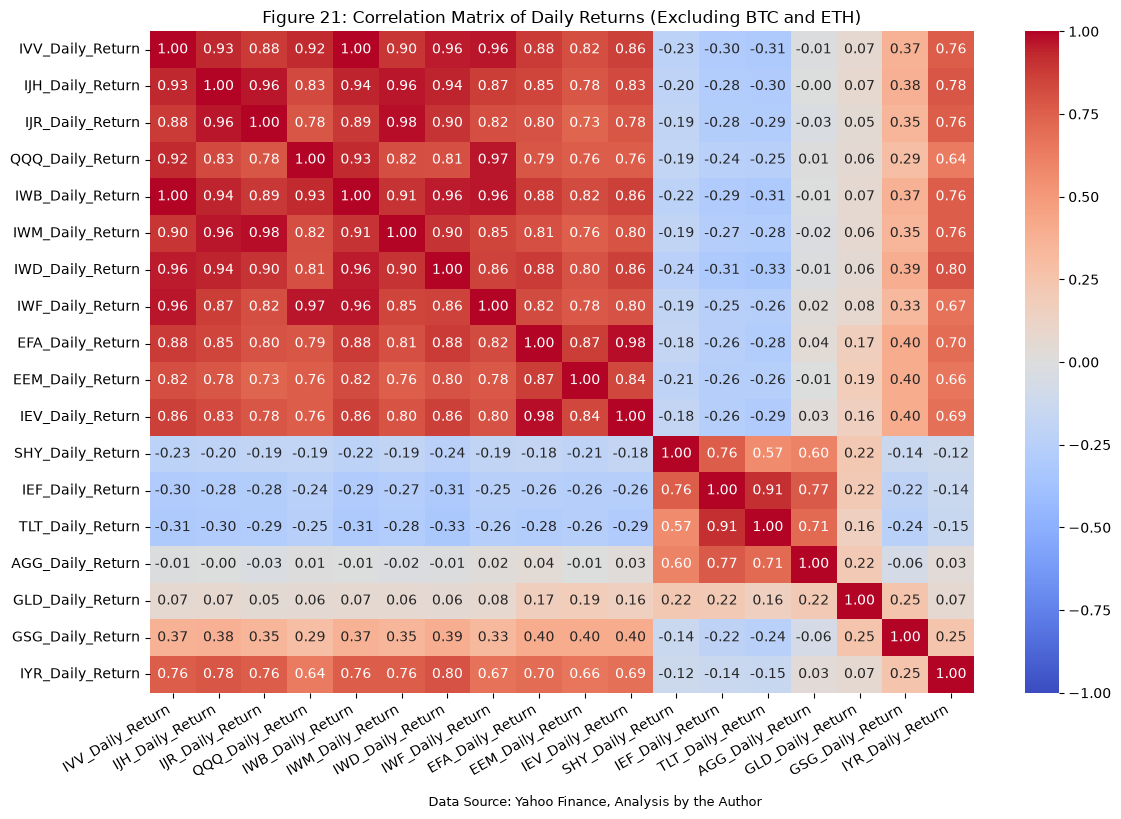

In [10]:
plot_heatmap(
    df=correlation_matrix_no_crypto,
    title=f"Figure {next(figure_number)}: Correlation Matrix of Daily Returns (Excluding BTC and ETH)",
    caption=f"Data Source: Yahoo Finance, Analysis by the Author",
)

We'll now include the BTC and ETH data and recalculate the correlation matrix and heatmap. Keep in mind that the BTC and ETH data only goes back to 2015 and 2018 respectively, so the correlation matrix will be calculated using a shorter time period than the other assets.

In [11]:
# Print the shape of the fund_data_daily_returns DataFrame to confirm that the rows with missing data have been dropped
print(f"Shape of fund_data_daily_returns: {fund_data_daily_returns_all.shape}")
print(f"Rows to drop due to missing data: {fund_data_daily_returns_all.dropna().shape}")

# Drop the NaN values
fund_data_daily_returns = fund_data_daily_returns_all.dropna()

# Calculate the correlation matrix of the daily returns
correlation_matrix = fund_data_daily_returns.corr()

display(Markdown(f"Table {next(table_number)}: Correlation Matrix of Daily Returns (Including BTC and ETH)"))
display(correlation_matrix)

Shape of fund_data_daily_returns: (8331, 20)
Rows to drop due to missing data: (2252, 20)


Table 3: Correlation Matrix of Daily Returns (Including BTC and ETH)

,IVV_Daily_Return,IJH_Daily_Return,IJR_Daily_Return,QQQ_Daily_Return,IWB_Daily_Return,IWM_Daily_Return,IWD_Daily_Return,IWF_Daily_Return,EFA_Daily_Return,EEM_Daily_Return,IEV_Daily_Return,SHY_Daily_Return,IEF_Daily_Return,TLT_Daily_Return,AGG_Daily_Return,GLD_Daily_Return,GSG_Daily_Return,IYR_Daily_Return,BTC-USD_Daily_Return,ETH-USD_Daily_Return
IVV_Daily_Return,1.00,0.90,0.84,0.93,1.00,0.86,0.93,0.96,0.85,0.75,0.82,-0.04,-0.11,-0.14,0.14,0.12,0.29,0.73,0.30,0.33
IJH_Daily_Return,0.90,1.00,0.96,0.77,0.91,0.96,0.94,0.81,0.83,0.71,0.81,-0.04,-0.10,-0.13,0.16,0.11,0.29,0.77,0.29,0.30
IJR_Daily_Return,0.84,0.96,1.00,0.71,0.85,0.98,0.90,0.73,0.78,0.66,0.76,-0.02,-0.09,-0.12,0.16,0.09,0.28,0.73,0.28,0.30
QQQ_Daily_Return,0.93,0.77,0.71,1.00,0.93,0.77,0.75,0.98,0.76,0.74,0.72,-0.02,-0.06,-0.09,0.14,0.14,0.22,0.57,0.31,0.34
IWB_Daily_Return,1.00,0.91,0.85,0.93,1.00,0.88,0.93,0.96,0.85,0.75,0.82,-0.04,-0.10,-0.13,0.15,0.12,0.28,0.73,0.30,0.33
IWM_Daily_Return,0.86,0.96,0.98,0.77,0.88,1.00,0.89,0.79,0.80,0.70,0.77,-0.01,-0.07,-0.10,0.17,0.13,0.28,0.72,0.31,0.33
IWD_Daily_Return,0.93,0.94,0.90,0.75,0.93,0.89,1.00,0.78,0.85,0.69,0.83,-0.05,-0.13,-0.17,0.13,0.11,0.32,0.80,0.26,0.28
IWF_Daily_Return,0.96,0.81,0.73,0.98,0.96,0.79,0.78,1.00,0.78,0.73,0.74,-0.02,-0.07,-0.09,0.15,0.12,0.22,0.62,0.31,0.34
EFA_Daily_Return,0.85,0.83,0.78,0.76,0.85,0.80,0.85,0.78,1.00,0.82,0.98,0.03,-0.03,-0.08,0.22,0.25,0.27,0.68,0.29,0.32
EEM_Daily_Return,0.75,0.71,0.66,0.74,0.75,0.70,0.69,0.73,0.82,1.00,0.79,0.01,-0.05,-0.08,0.16,0.27,0.26,0.51,0.26,0.30


And then the heatmap:

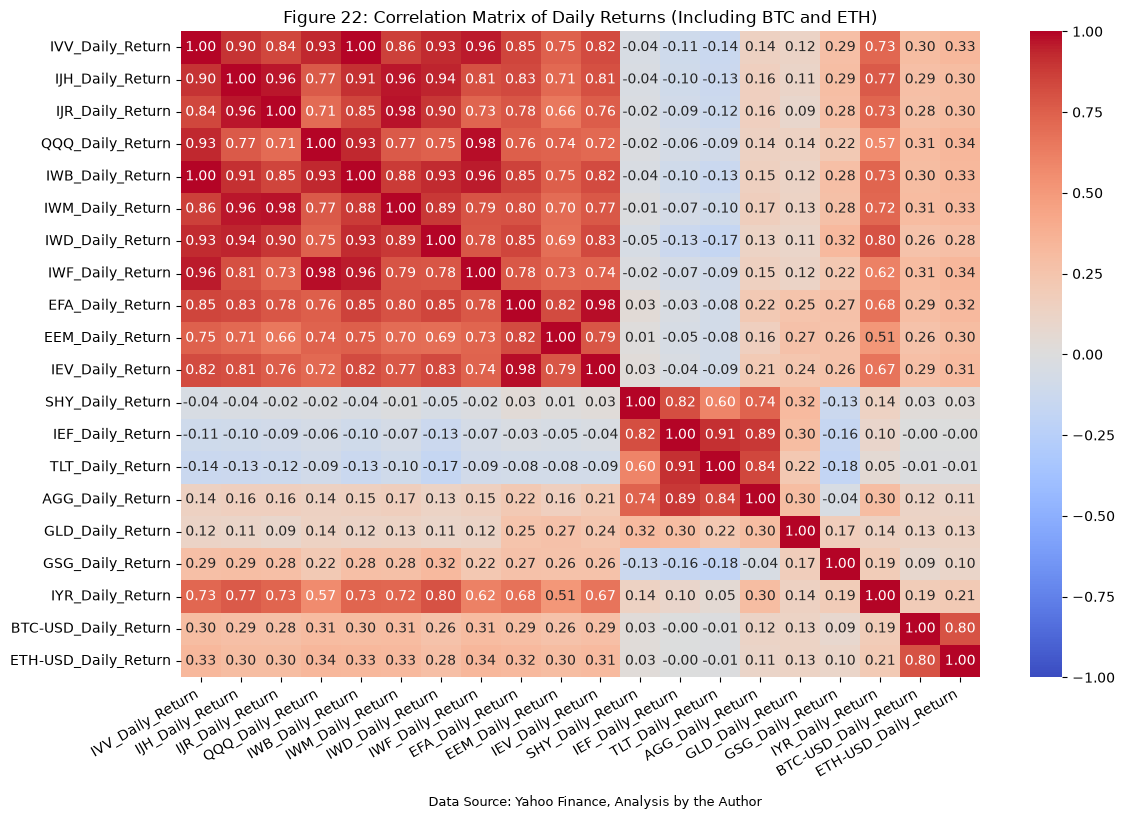

In [12]:
plot_heatmap(
    df=correlation_matrix,
    title=f"Figure {next(figure_number)}: Correlation Matrix of Daily Returns (Including BTC and ETH)",
    caption=f"Data Source: Yahoo Finance, Analysis by the Author",
)

These are interesting results, but expected. The stock funds tend to have low correlations with the bond funds, the commodities don't really correlate with anything, etc. But we know that the correlations between these asset classes have changed over time, so let's take a look at how the correlations have evolved over time by calculating rolling correlations.

## Calculate Rolling Correlations

Next, we will calculate the rolling correlations for several different periods:

* 3 days
* 1 week
* 2 weeks
* 1 month
* 3 month
* 6 month
* 1 year
* 5 years
* 10 years

In [13]:
# Define rolling windows in trading days
rolling_windows = {
    "3d": 3,  # 3 days (~3 trading days)
    "1w": 5,  # 1 week (~5 trading days)
    "2w": 10,  # 2 weeks (~10 trading days)
    "1m": 21,  # 1 month (~21 trading days)
    "3m": 63,  # 3 months (~63 trading days)
    "6m": 126,  # 6 months (~126 trading days)
    "1y": 252,  # 1 year (~252 trading days)
    "5y": 1260,  # 5 years (~1260 trading days)
    "10y": 2520,  # 10 years (~2520 trading days)
}

We'll pair down the list of funds to only include the high correlation US equity funds that make up the S&P 1500 index (IVV, IJH, IJR).

In [14]:
# Create temp list for tickers
tickers = ["IVV", "IJH", "IJR"]
pairs = list(combinations(tickers, 2))

# Create empty dictionary to store rolling correlation results
rolling_corr_results = {}

# Create empty DataFrame to store rolling correlation results
rolling_corr_results_df = pd.DataFrame()

# Calculate rolling correlations for each pair of tickers and each rolling window
for ticker1, ticker2 in pairs:
    try:
        temp_df = fund_data_daily_returns_no_crypto[
            [f"{ticker1}_Daily_Return", f"{ticker2}_Daily_Return"]
        ].dropna()
    except Exception as e:
        print(f"Error creating temp_df for {ticker1} and {ticker2}: {e}")
        continue

    for window_name, window_size in rolling_windows.items():
        try:
            rolling_corr = (
                temp_df[f"{ticker1}_Daily_Return"]
                .rolling(window=window_size)
                .corr(temp_df[f"{ticker2}_Daily_Return"])
            )

            # print(tickers_dict[f"{ticker1}"])
            # print(tickers_dict[f"{ticker2}"])

            rolling_corr_results[
                f"{ticker1}_{ticker2}_{window_name}"
            ] = rolling_corr
            rolling_corr_results_df = pd.concat(
                [
                    rolling_corr_results_df,
                    rolling_corr.to_frame(name=f"{ticker1}_{ticker2}_{window_name}"),
                ],
                axis=1,
            )

        except Exception as e:
            print(
                f"Error calculating rolling correlation for {ticker1} and {ticker2} with window {window_name}: {e}"
            )

display(Markdown(f"Table {next(table_number)}: Rolling Correlations"))
display(rolling_corr_results_df)

Table 4: Rolling Correlations

,IVV_IJH_3d,IVV_IJH_1w,IVV_IJH_2w,IVV_IJH_1m,IVV_IJH_3m,IVV_IJH_6m,IVV_IJH_1y,IVV_IJH_5y,IVV_IJH_10y,IVV_IJR_3d,...,IVV_IJR_10y,IJH_IJR_3d,IJH_IJR_1w,IJH_IJR_2w,IJH_IJR_1m,IJH_IJR_3m,IJH_IJR_6m,IJH_IJR_1y,IJH_IJR_5y,IJH_IJR_10y
Date,,,,,,,,,,,,,,,,,,,,,
2006-07-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-26,0.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.96,...,NaN,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-27,0.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.93,...,NaN,0.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-28,1.00,0.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.99,...,NaN,0.98,0.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-22,0.90,0.87,0.87,0.75,0.79,0.78,0.80,0.88,0.90,-0.05,...,0.83,0.39,0.65,0.82,0.86,0.91,0.90,0.93,0.97,0.96
2026-10-23,0.98,0.83,0.86,0.76,0.80,0.78,0.80,0.88,0.90,-0.45,...,0.83,-0.25,0.53,0.84,0.86,0.90,0.90,0.93,0.97,0.96
2026-10-26,0.98,0.91,0.89,0.78,0.80,0.78,0.80,0.88,0.90,0.07,...,0.83,0.28,0.54,0.83,0.86,0.91,0.90,0.93,0.97,0.96


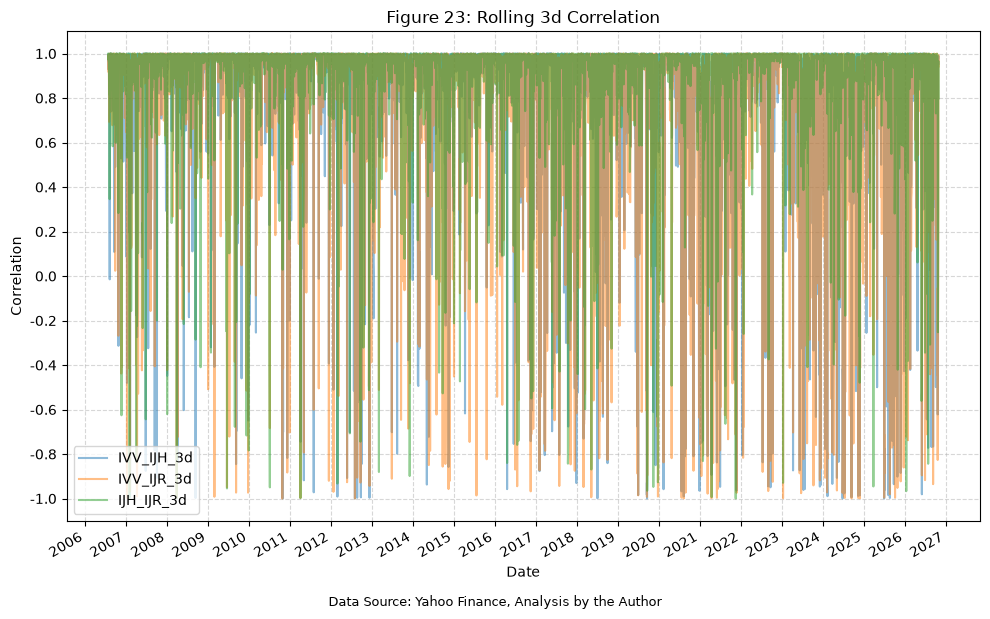

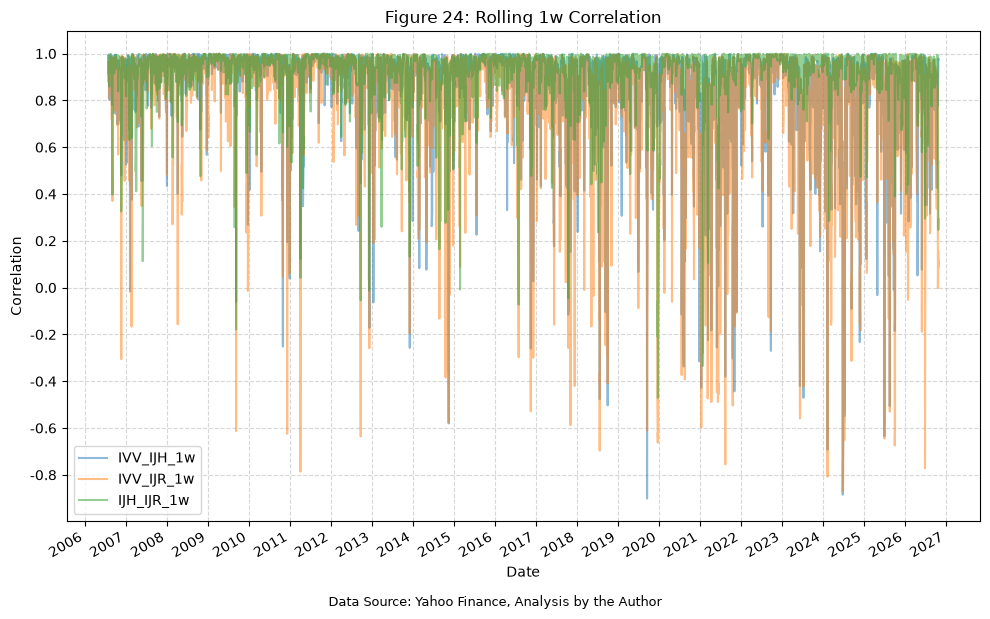

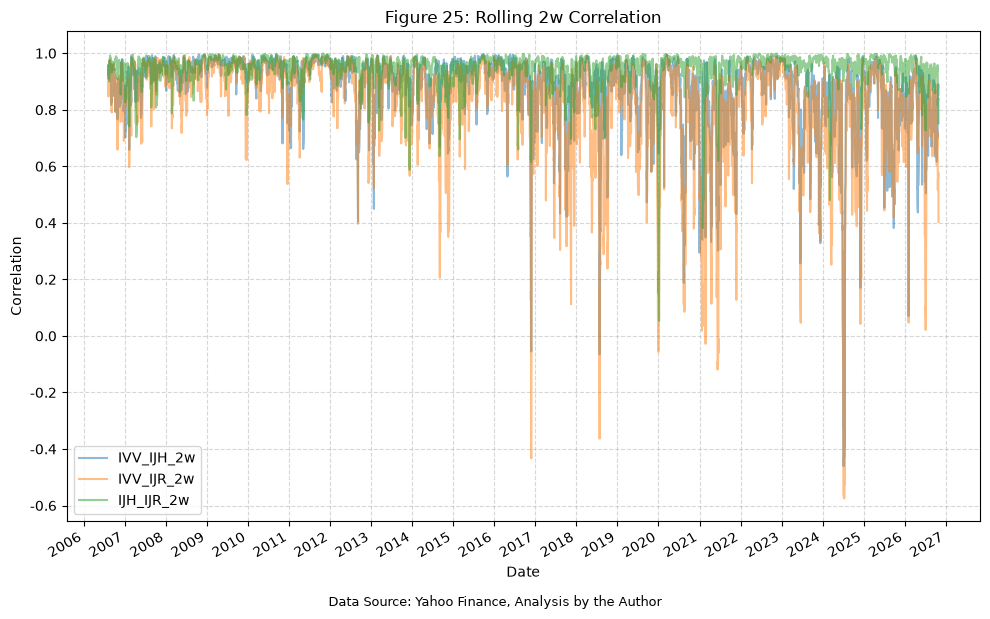

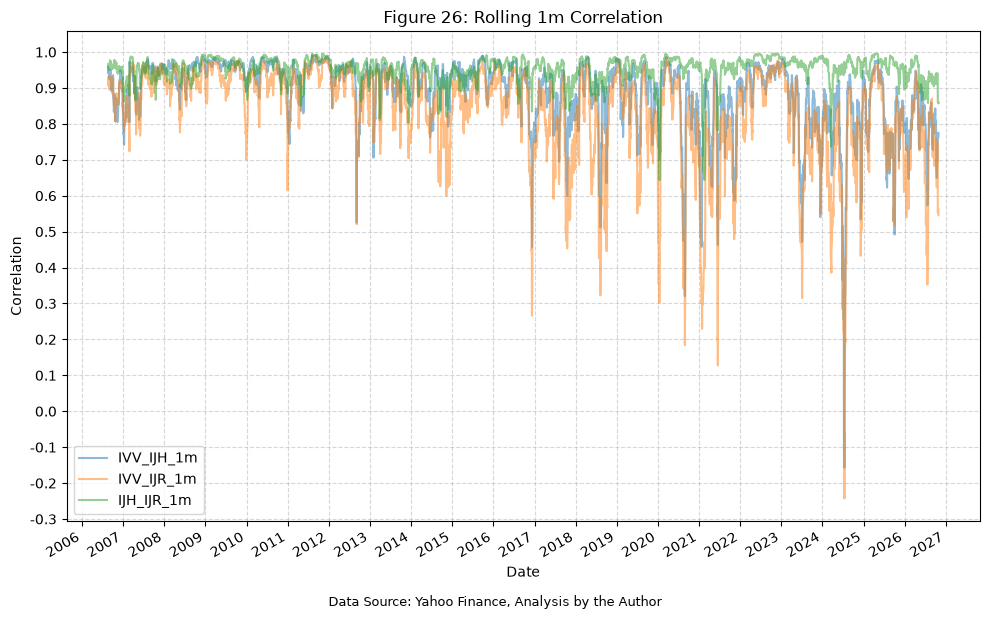

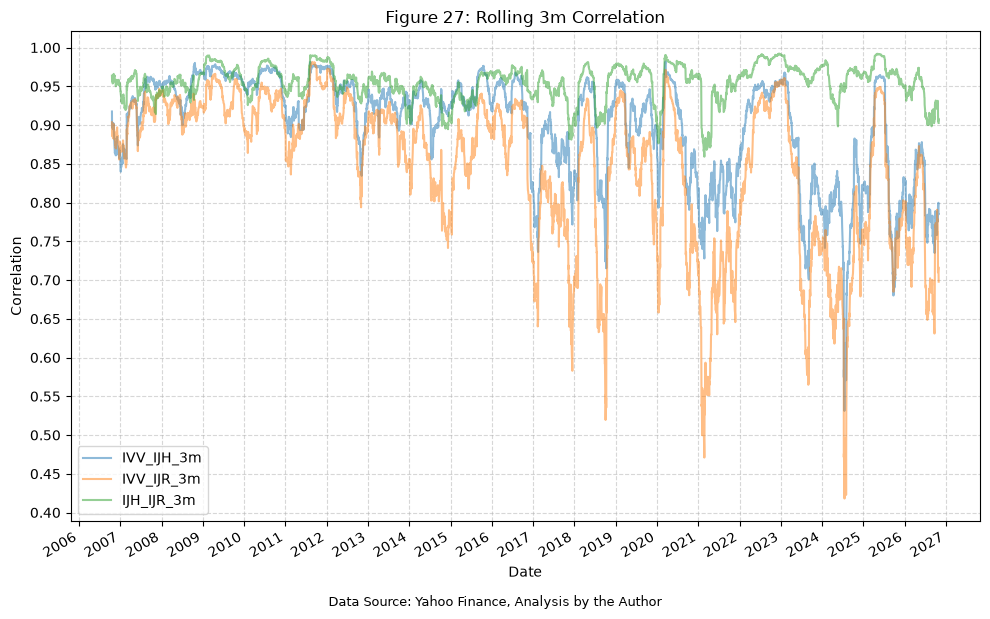

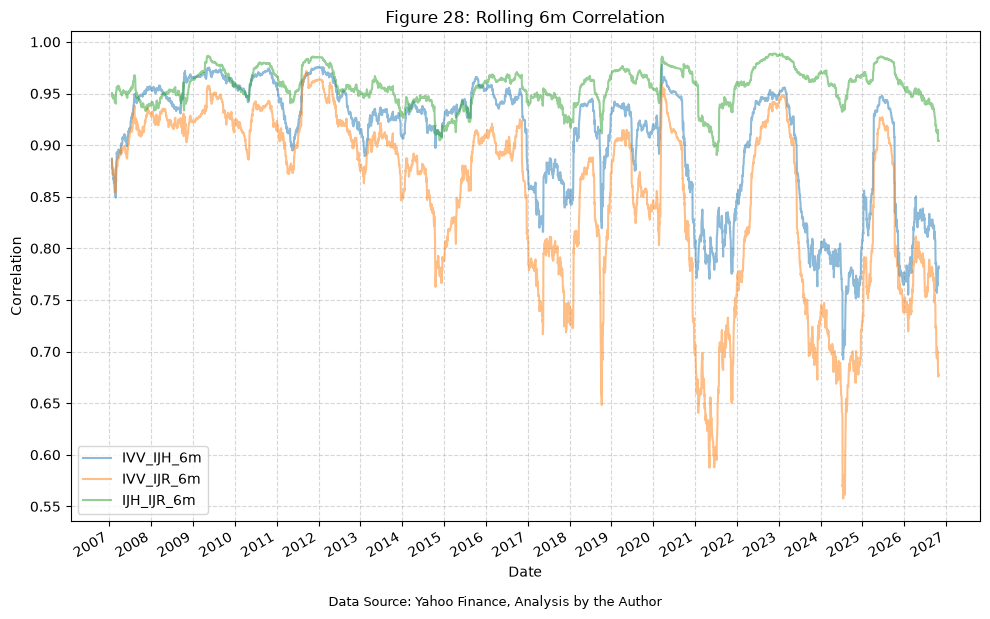

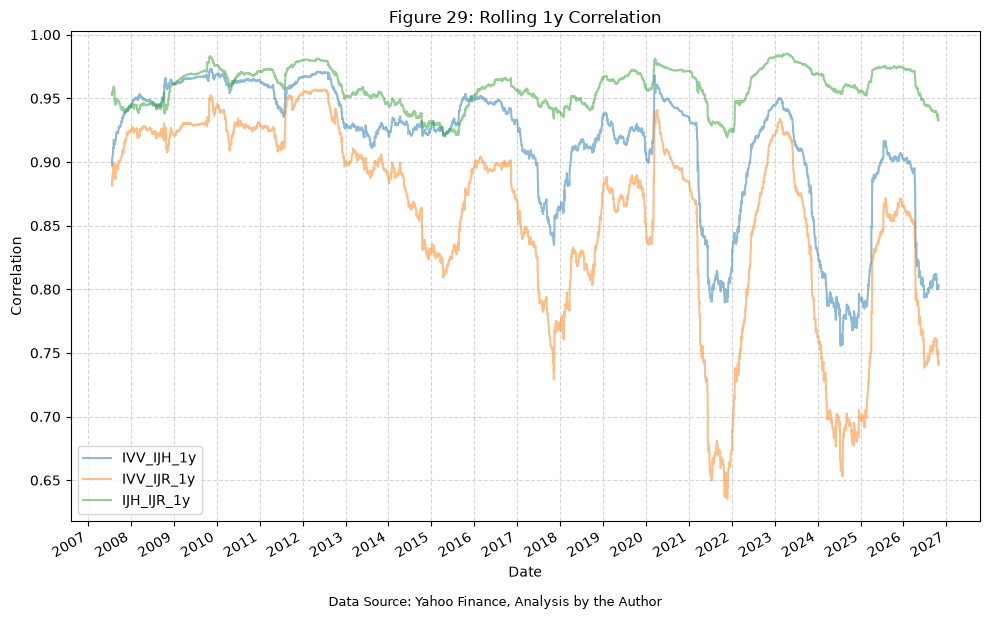

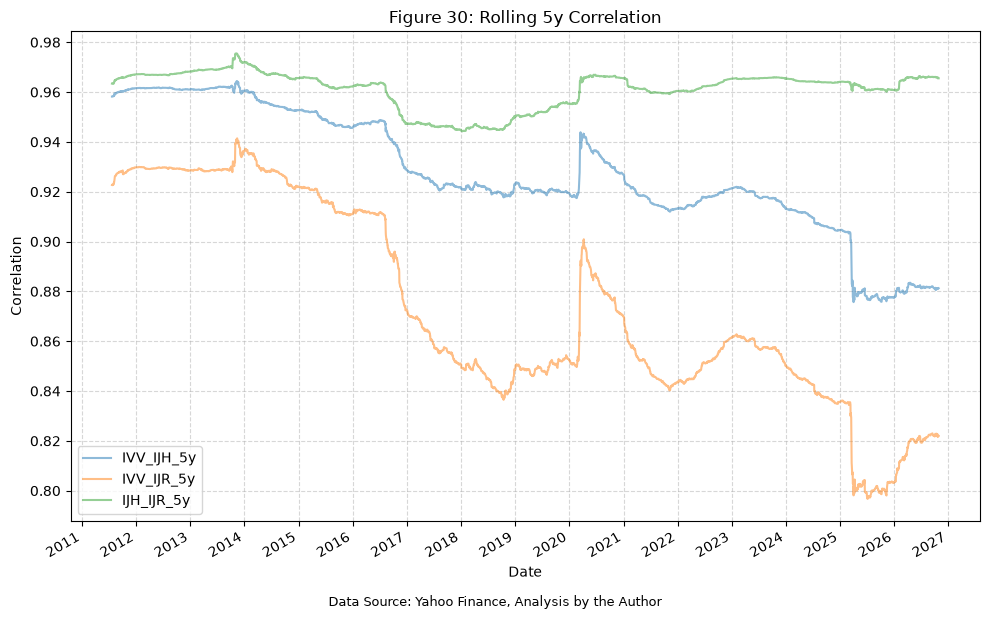

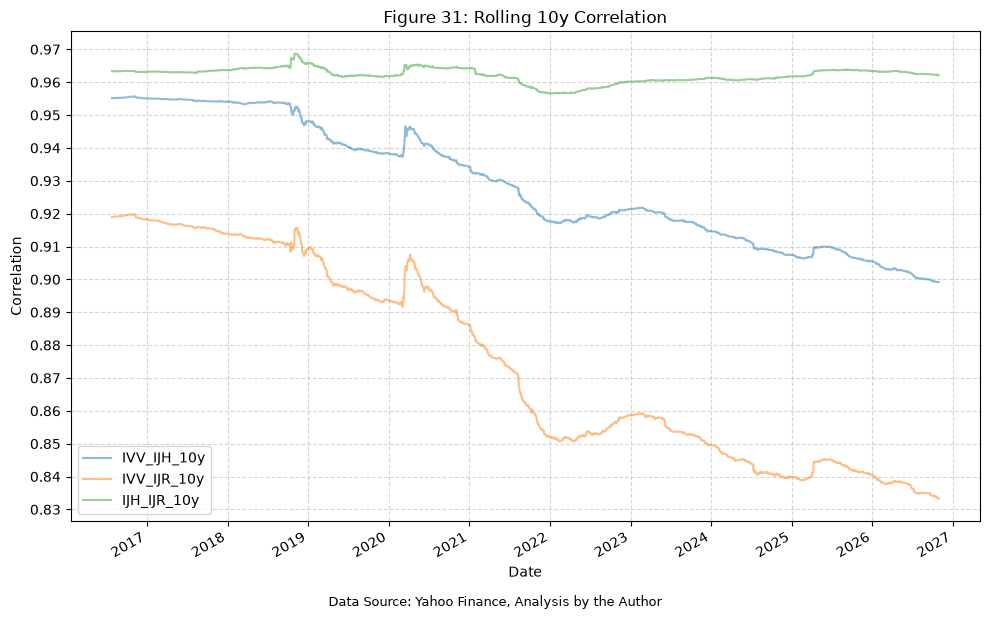

In [15]:
for window in rolling_windows.keys():
    plot_time_series(
        df=rolling_corr_results_df,
        plot_start_date=None,
        plot_end_date=None,
        plot_columns=[col for col in rolling_corr_results_df.columns if f"{window}" in col],
        title=f"Figure {next(figure_number)}: Rolling {window} Correlation",
        x_label="Date",
        x_format="Year",
        x_tick_spacing=1,
        x_tick_start=None,
        x_tick_rotation=30,
        y_label="Correlation",
        y_format="Decimal",
        y_format_decimal_places="Auto",
        y_tick_spacing="Auto",
        y_tick_rotation=0,
        grid=True,
        legend=True,
        export_plot=False,
        plot_file_name=None,
        caption=f"Data Source: Yahoo Finance, Analysis by the Author",
    )

## Total Correlation Metric

With the above plots, we can see that there are periods of time when the correlations abruptly increase or decrease, such as:

* Early-mid 2007 (the start of the financial crisis)
* Mid 2011 (the European debt crisis)
* Late 2015 into 2016
* Late 2018 (rate hikes?)
* Early 2020 (COVID-19 pandemic)
* Late 2022 into early 2023 (rate hikes, recession fears, COVID tech bubble, etc.)
* Mid 2024 (banking crisis, rate hikes)
* Early 2025 (Liberation day)

We're not necessarily looking to explain away each of these time periods or delve into the macro factors that may have been at play or driving the correlations, but we are more interested in the change in correlation over time as a response to some kind of market shock or event.

As an attempt to find some kind of signal, let's simply add the correlations together to get a "total correlation" metric, and look at the distribution. Note that we normalize the correlations to account for the number of correlations being summed by dividing the total by the number of correlations, to keep the values between -1 and 1.

In [16]:
# Calculate total rolling correlation for each window
for window, days in rolling_windows.items():
    rolling_corr_results_df[f"total_rolling_correlation_{window}"] = rolling_corr_results_df[[col for col in rolling_corr_results_df.columns if col.endswith(f"_{window}")]].sum(axis=1) / len([col for col in rolling_corr_results_df.columns if col.endswith(f"_{window}")])

# Reset any 0.00 values to NaN
rolling_corr_results_df.replace(0.00, np.nan, inplace=True)

,IVV_IJH_3d,IVV_IJH_1w,IVV_IJH_2w,IVV_IJH_1m,IVV_IJH_3m,IVV_IJH_6m,IVV_IJH_1y,IVV_IJH_5y,IVV_IJH_10y,IVV_IJR_3d,...,IJH_IJR_10y,total_rolling_correlation_3d,total_rolling_correlation_1w,total_rolling_correlation_2w,total_rolling_correlation_1m,total_rolling_correlation_3m,total_rolling_correlation_6m,total_rolling_correlation_1y,total_rolling_correlation_5y,total_rolling_correlation_10y
Date,,,,,,,,,,,,,,,,,,,,,
2006-07-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-26,0.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.96,...,NaN,0.98,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-27,0.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.93,...,NaN,0.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-28,1.00,0.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.99,...,NaN,0.99,0.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-22,0.90,0.87,0.87,0.75,0.79,0.78,0.80,0.88,0.90,-0.05,...,0.96,0.41,0.61,0.73,0.72,0.80,0.79,0.83,0.89,0.90
2026-10-23,0.98,0.83,0.86,0.76,0.80,0.78,0.80,0.88,0.90,-0.45,...,0.96,0.09,0.45,0.75,0.73,0.80,0.79,0.83,0.89,0.90
2026-10-26,0.98,0.91,0.89,0.78,0.80,0.78,0.80,0.88,0.90,0.07,...,0.96,0.44,0.54,0.76,0.73,0.81,0.79,0.83,0.89,0.90


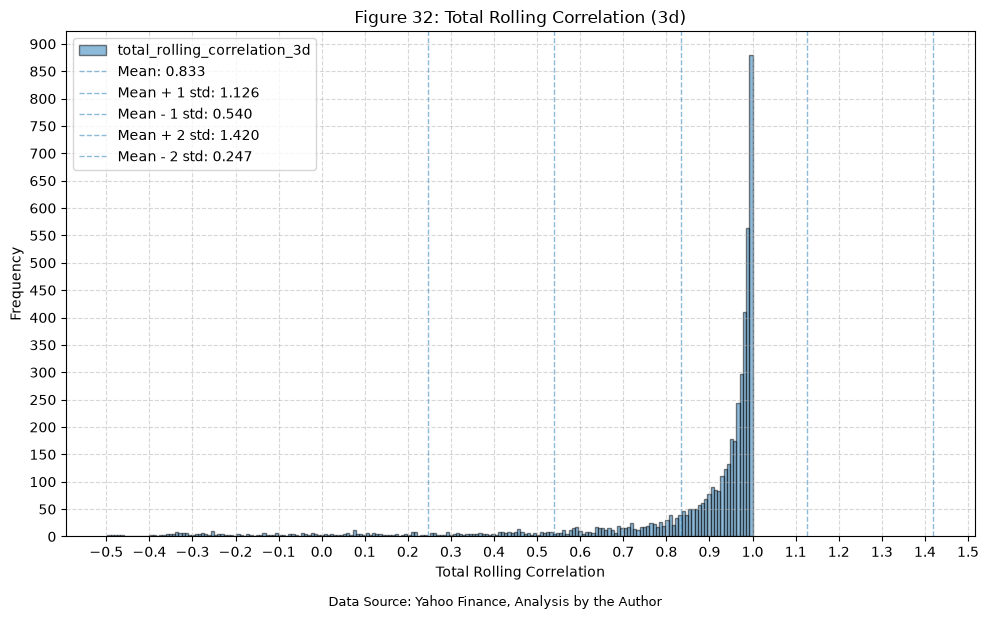

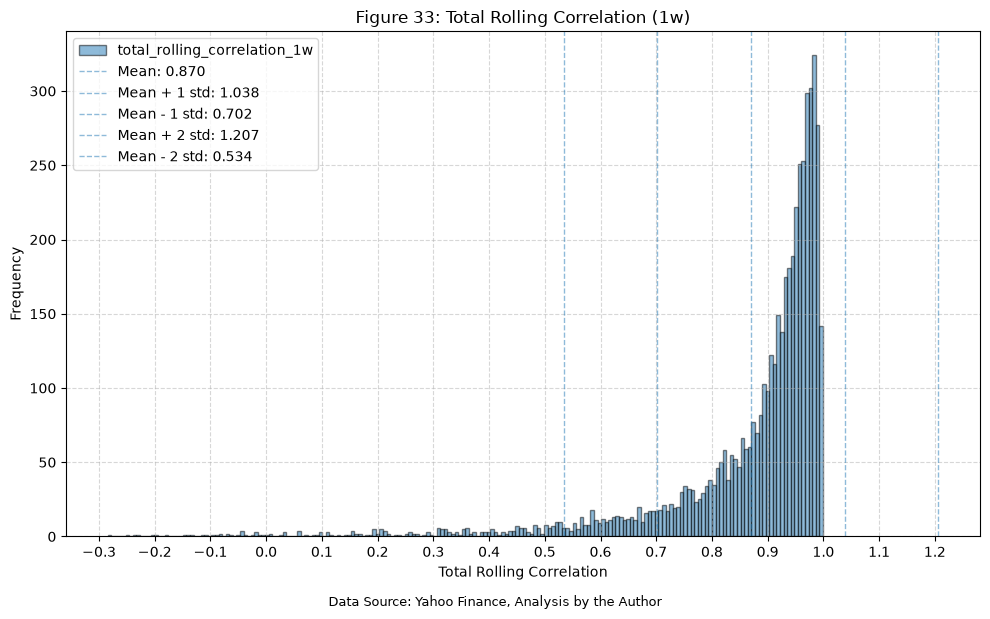

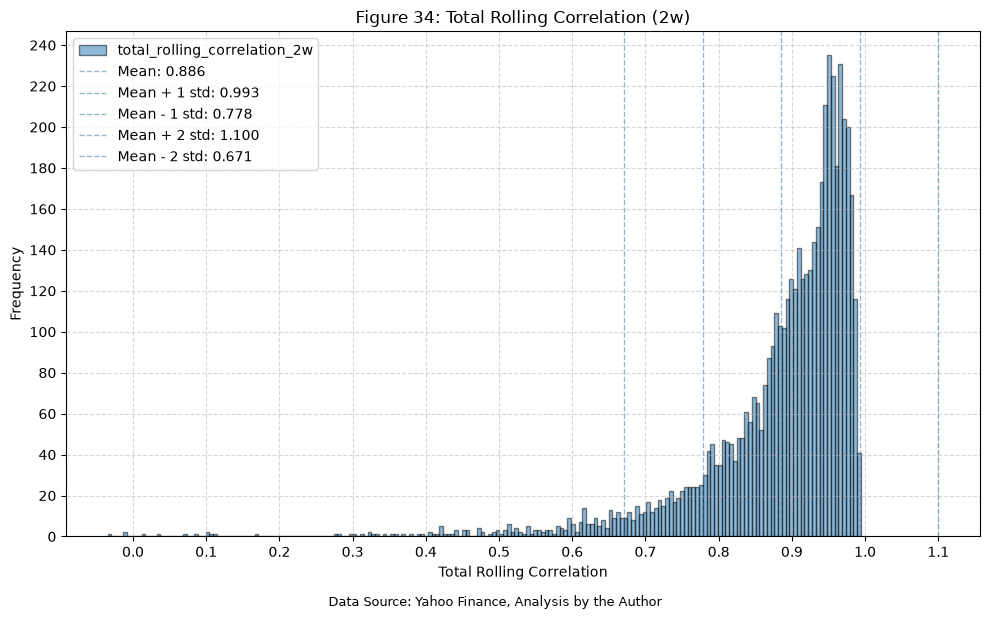

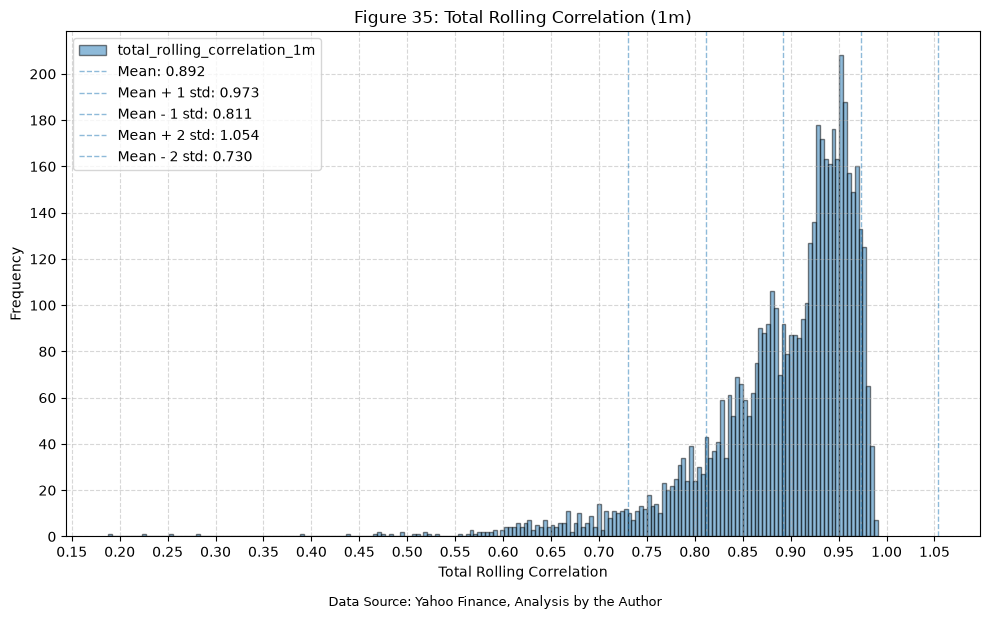

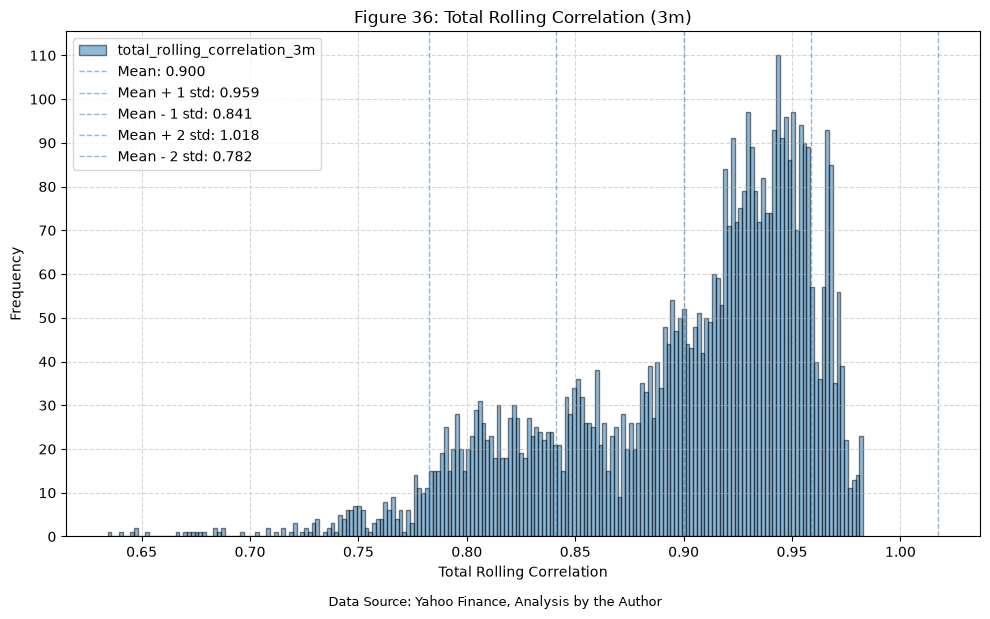

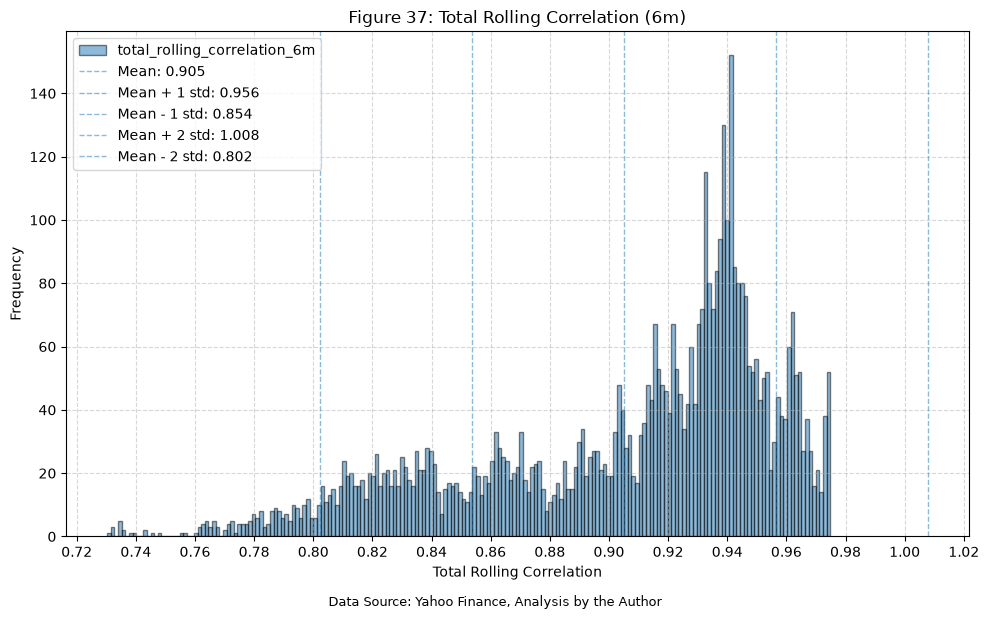

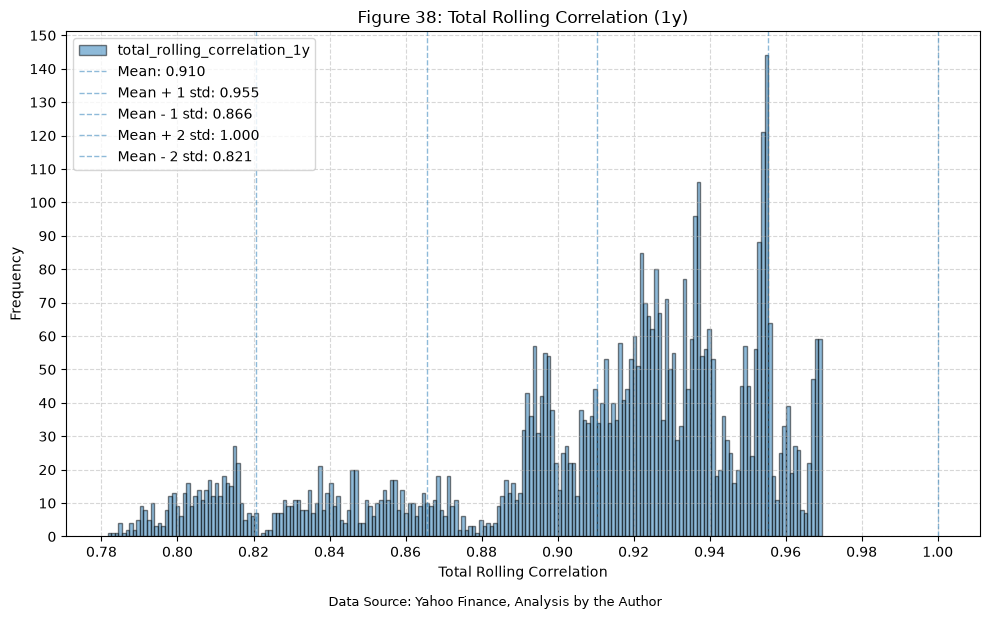

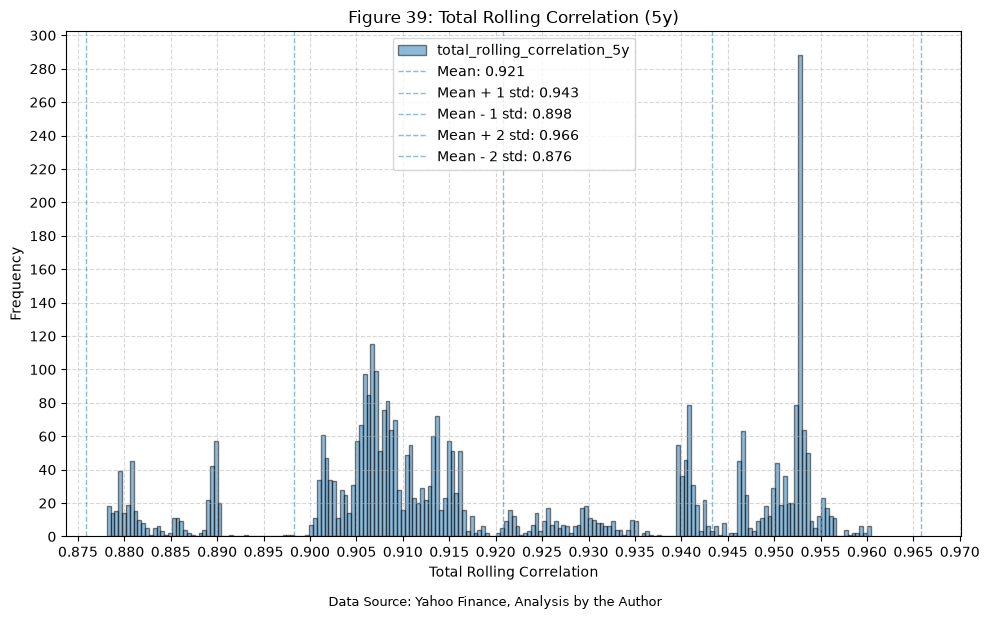

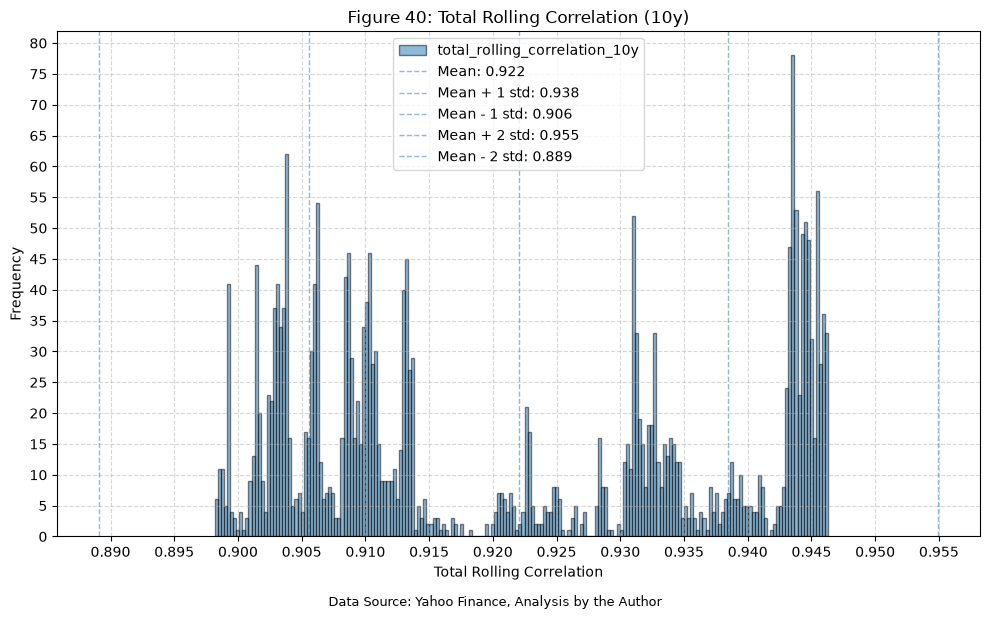

In [17]:
for window in rolling_windows.keys():
    plot_histogram(
        df=rolling_corr_results_df[[f"total_rolling_correlation_{window}"]].dropna(),
        plot_columns=[f"total_rolling_correlation_{window}"],
        title=f"Figure {next(figure_number)}: Total Rolling Correlation ({window})",
        x_label="Total Rolling Correlation",
        x_tick_spacing="Auto",
        x_tick_rotation=0,
        y_label="Frequency",
        y_tick_spacing="Auto",
        y_tick_rotation=0,
        caption=f"Data Source: Yahoo Finance, Analysis by the Author",
    )

Alright, so the distributions for 1w, 2w, and 1m look interesting. For each of those windows, let's look at the different deciles of the rolling correlations, and what that implies for future returns.

## Future Returns Based On Total Rolling Correlation

First, we need to define the forward return windows that we want to look at.

In [18]:
# Define rolling windows in trading days
return_windows = {
    "1d": 1,  # 1 day (~1 trading day)
    "3d": 3,  # 3 days (~3 trading days)
    "1w": 5,  # 1 week (~5 trading days)
    "2w": 10,  # 2 weeks (~10 trading days)
    "1m": 21,  # 1 month (~21 trading days)
    "2m": 42,  # 2 months (~42 trading days)
    "3m": 63,  # 3 months (~63 trading days)
}

Then, we'll merge in the returns and create the forward returns for each of the funds.

In [19]:
# Merge daily returns in for the ETFs
total_rolling_corr_with_returns = rolling_corr_results_df.merge(
    fund_data_daily_returns_all[
        [f"{ft}_Daily_Return" for ft in tickers]
    ].dropna(),
    left_index=True,
    right_index=True,
    how="left",
)

# Calculate compounded rolling returns (CRR), and then shift to create forward returns
for rw in return_windows.keys():
    for ft in tickers:
        total_rolling_corr_with_returns[f"{ft}_Daily_Return_{rw}_CRR"] = (
            total_rolling_corr_with_returns[f"{ft}_Daily_Return"]
            .rolling(window=return_windows[rw])
            .apply(lambda x: (1 + x).prod() - 1, raw=True)
        )
        total_rolling_corr_with_returns[f"{ft}_Daily_Return_fwd_{rw}_CRR"] = total_rolling_corr_with_returns[
            f"{ft}_Daily_Return_{rw}_CRR"
        ].shift(-return_windows[rw])

display(Markdown(f"Table {next(table_number)}: Total Rolling Correlations With Forward Returns"))
display(total_rolling_corr_with_returns)

Table 5: Total Rolling Correlations With Forward Returns

,IVV_IJH_3d,IVV_IJH_1w,IVV_IJH_2w,IVV_IJH_1m,IVV_IJH_3m,IVV_IJH_6m,IVV_IJH_1y,IVV_IJH_5y,IVV_IJH_10y,IVV_IJR_3d,...,IJH_Daily_Return_2m_CRR,IJH_Daily_Return_fwd_2m_CRR,IJR_Daily_Return_2m_CRR,IJR_Daily_Return_fwd_2m_CRR,IVV_Daily_Return_3m_CRR,IVV_Daily_Return_fwd_3m_CRR,IJH_Daily_Return_3m_CRR,IJH_Daily_Return_fwd_3m_CRR,IJR_Daily_Return_3m_CRR,IJR_Daily_Return_fwd_3m_CRR
Date,,,,,,,,,,,,,,,,,,,,,
2006-07-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.03,NaN,0.04,NaN,0.09,NaN,0.07,NaN,0.08
2006-07-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.01,NaN,0.02,NaN,0.09,NaN,0.07,NaN,0.08
2006-07-26,0.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.96,...,NaN,0.02,NaN,0.04,NaN,0.09,NaN,0.07,NaN,0.09
2006-07-27,0.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.93,...,NaN,0.04,NaN,0.06,NaN,0.10,NaN,0.09,NaN,0.11
2006-07-28,1.00,0.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.99,...,NaN,0.03,NaN,0.05,NaN,0.09,NaN,0.08,NaN,0.10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-22,0.90,0.87,0.87,0.75,0.79,0.78,0.80,0.88,0.90,-0.05,...,-0.04,NaN,-0.05,NaN,0.04,NaN,-0.04,NaN,-0.04,NaN
2026-10-23,0.98,0.83,0.86,0.76,0.80,0.78,0.80,0.88,0.90,-0.45,...,-0.05,NaN,-0.05,NaN,0.03,NaN,-0.04,NaN,-0.05,NaN
2026-10-26,0.98,0.91,0.89,0.78,0.80,0.78,0.80,0.88,0.90,0.07,...,-0.05,NaN,-0.05,NaN,0.04,NaN,-0.04,NaN,-0.05,NaN


### Summary By Decile

Before looking at the individual plots, here is a summary of the forward returns for each decile of total rolling correlation compared with the baseline (all days). Values are in percent.

In [20]:
analysis_windows = ["1w", "2w", "1m"]
decile_labels = [f"D{i}" for i in range(1, 11)]

decile_summary = {}

for window in analysis_windows:
    col = f"total_rolling_correlation_{window}"
    df = total_rolling_corr_with_returns.dropna(subset=[col])

    # Assign each day to a correlation decile and record each decile's range
    bucket = pd.qcut(df[col], 10, labels=decile_labels)
    ranges = df[col].groupby(bucket, observed=True).agg(["min", "max"])
    row_labels = ["Baseline (all days)"] + [
        f"{d} ({ranges.loc[d, 'min']:.2f} to {ranges.loc[d, 'max']:.2f})" for d in decile_labels
    ]

    pct_positive = {}
    mean_return = {}
    for rw in return_windows.keys():
        for ft in tickers:
            fwd = df[f"{ft}_Daily_Return_fwd_{rw}_CRR"]
            valid = fwd.notna()
            fwd, b = fwd[valid], bucket[valid]
            pct_positive[(rw, ft)] = [(fwd > 0).mean() * 100] + list(fwd.gt(0).groupby(b, observed=True).mean() * 100)
            mean_return[(rw, ft)] = [fwd.mean() * 100] + list(fwd.groupby(b, observed=True).mean() * 100)

    decile_summary[window] = {
        "pct_positive": pd.DataFrame(pct_positive, index=row_labels),
        "mean_return": pd.DataFrame(mean_return, index=row_labels),
    }

In [21]:
for window in analysis_windows:
    display(Markdown(f"Table {next(table_number)}: Percentage of Positive Future Returns by {window} Total Rolling Correlation Decile"))
    display(decile_summary[window]["pct_positive"])
    display(Markdown(f"Table {next(table_number)}: Mean Future Return (%) by {window} Total Rolling Correlation Decile"))
    display(decile_summary[window]["mean_return"])

Table 6: Percentage of Positive Future Returns by 1w Total Rolling Correlation Decile

1d                3d                1w              \
                      IVV   IJH   IJR   IVV   IJH   IJR   IVV   IJH   IJR   
Baseline (all days) 54.85 53.67 52.32 58.76 55.40 54.01 60.16 56.94 55.01   
D1 (-0.28 to 0.68)  54.03 47.94 46.95 57.79 50.10 47.14 60.59 54.06 49.31   
D2 (0.68 to 0.81)   56.58 54.81 52.06 57.96 55.21 51.08 57.56 54.81 50.88   
D3 (0.81 to 0.87)   54.51 49.80 50.59 57.45 53.53 52.55 60.39 55.10 54.31   
D4 (0.87 to 0.91)   55.99 58.94 58.15 62.08 57.17 56.58 63.06 60.31 59.72   
D5 (0.91 to 0.93)   59.41 58.43 55.88 61.18 57.65 57.06 60.59 55.88 53.73   
D6 (0.93 to 0.95)   49.31 49.51 48.33 54.22 51.87 51.47 56.58 54.62 53.83   
D7 (0.95 to 0.96)   54.22 54.42 53.44 61.30 60.31 58.94 63.46 60.51 58.15   
D8 (0.96 to 0.97)   53.33 52.94 50.98 58.63 55.29 53.92 59.41 59.02 55.10   
D9 (0.97 to 0.98)   55.80 56.39 54.03 59.14 57.17 55.60 59.33 57.56 56.78   
D10 (0.98 to 1.00)  55.29 53.53 52.75 57.84 55.69 55.69 60.59 57.45 58.24   

                       2w  ...          1m                2m              \
                      IVV  ...   IJR   IVV   IJH   IJR   IVV   IJH   IJR   
Baseline (all days) 63.87  ... 57.27 67.64 62.34 60.84 71.70 67.11 65.64   
D1 (-0.28 to 0.68)  67.33  ... 56.24 68.92 56.77 54.38 73.71 64.54 61.95   
D2 (0.68 to 0.81)   64.37  ... 53.54 67.19 59.49 57.51 74.30 68.07 66.27   
D3 (0.81 to 0.87)   64.51  ... 55.88 68.18 61.07 58.30 72.56 66.20 63.02   
D4 (0.87 to 0.91)   59.57  ... 55.03 67.26 60.75 58.58 69.25 65.28 66.27   
D5 (0.91 to 0.93)   66.40  ... 57.17 66.86 63.91 62.13 68.91 64.36 63.17   
D6 (0.93 to 0.95)   57.87  ... 55.51 62.40 61.22 59.84 66.27 63.31 62.52   
D7 (0.95 to 0.96)   68.96  ... 58.74 69.35 64.44 63.46 71.54 68.18 63.83   
D8 (0.96 to 0.97)   62.16  ... 57.65 68.63 65.49 64.71 73.33 69.22 68.63   
D9 (0.97 to 0.98)   65.62  ... 61.49 67.19 63.46 64.24 73.23 69.69 70.28   
D10 (0.98 to 1.00)  61.96  ... 61.37 70.39 66.67 65.10 73.92 72.16 70.39   

                       3m              
                      IVV   IJH   IJR  
Baseline (all days) 73.91 69.50 66.71  
D1 (-0.28 to 0.68)  78.20 68.60 64.40  
D2 (0.68 to 0.81)   76.83 71.95 68.50  
D3 (0.81 to 0.87)   76.40 71.20 68.60  
D4 (0.87 to 0.91)   75.15 68.19 66.80  
D5 (0.91 to 0.93)   70.58 64.02 63.02  
D6 (0.93 to 0.95)   66.67 63.49 60.32  
D7 (0.95 to 0.96)   72.96 71.37 68.59  
D8 (0.96 to 0.97)   72.10 71.91 68.37  
D9 (0.97 to 0.98)   72.64 68.70 66.54  
D10 (0.98 to 1.00)  77.65 75.49 71.96  

[11 rows x 21 columns]

Table 7: Mean Future Return (%) by 1w Total Rolling Correlation Decile

1d                3d               1w              2w  \
                      IVV   IJH   IJR   IVV   IJH   IJR  IVV  IJH   IJR  IVV   
Baseline (all days)  0.05  0.05  0.05  0.15  0.14  0.14 0.24 0.23  0.23 0.48   
D1 (-0.28 to 0.68)   0.07  0.05  0.03  0.13  0.05  0.04 0.27 0.23  0.25 0.56   
D2 (0.68 to 0.81)    0.06  0.04  0.04  0.13  0.10  0.07 0.14 0.04 -0.01 0.38   
D3 (0.81 to 0.87)   -0.00 -0.03 -0.03  0.09  0.03  0.03 0.14 0.05  0.06 0.39   
D4 (0.87 to 0.91)    0.11  0.10  0.08  0.26  0.25  0.23 0.32 0.31  0.29 0.34   
D5 (0.91 to 0.93)    0.13  0.17  0.17  0.25  0.28  0.26 0.31 0.34  0.29 0.63   
D6 (0.93 to 0.95)   -0.08 -0.11 -0.11 -0.04 -0.07 -0.04 0.09 0.11  0.13 0.11   
D7 (0.95 to 0.96)    0.04  0.06  0.07  0.35  0.38  0.38 0.48 0.48  0.47 0.87   
D8 (0.96 to 0.97)    0.08  0.11  0.13  0.10  0.17  0.15 0.16 0.22  0.22 0.30   
D9 (0.97 to 0.98)    0.04  0.04  0.06  0.08  0.09  0.14 0.28 0.31  0.35 0.76   
D10 (0.98 to 1.00)   0.04  0.05  0.05  0.11  0.11  0.12 0.24 0.19  0.23 0.49   

                     ...        1m             2m             3m            
                     ...  IJR  IVV  IJH  IJR  IVV  IJH  IJR  IVV  IJH  IJR  
Baseline (all days)  ... 0.45 1.01 0.95 0.95 2.02 1.90 1.88 3.01 2.85 2.82  
D1 (-0.28 to 0.68)   ... 0.70 0.97 0.70 0.81 1.90 1.44 1.38 2.95 1.93 1.51  
D2 (0.68 to 0.81)    ... 0.15 0.85 0.42 0.34 1.82 1.42 1.44 2.93 2.39 2.42  
D3 (0.81 to 0.87)    ... 0.22 0.89 0.70 0.66 1.83 1.40 1.25 3.17 2.71 2.71  
D4 (0.87 to 0.91)    ... 0.34 0.66 0.57 0.61 1.70 1.52 1.68 2.60 2.33 2.45  
D5 (0.91 to 0.93)    ... 0.54 1.08 1.08 1.03 1.71 1.50 1.37 2.27 2.04 1.96  
D6 (0.93 to 0.95)    ... 0.09 0.55 0.71 0.70 0.82 0.74 0.77 1.68 1.73 1.81  
D7 (0.95 to 0.96)    ... 0.79 1.38 1.41 1.36 2.13 2.24 2.15 3.27 3.48 3.52  
D8 (0.96 to 0.97)    ... 0.29 0.93 0.98 0.94 2.34 2.48 2.45 3.31 3.40 3.35  
D9 (0.97 to 0.98)    ... 0.82 1.22 1.29 1.32 2.49 2.60 2.64 3.35 3.41 3.36  
D10 (0.98 to 1.00)   ... 0.56 1.59 1.67 1.67 3.43 3.65 3.67 4.56 5.06 5.08  

[11 rows x 21 columns]

Table 8: Percentage of Positive Future Returns by 2w Total Rolling Correlation Decile

...

1d              3d               1w               2w  \
                     IVV  IJH   IJR  IVV   IJH   IJR  IVV   IJH   IJR  IVV   
Baseline (all days) 0.05 0.05  0.05 0.15  0.14  0.14 0.24  0.23  0.23 0.48   
D1 (-0.03 to 0.76)  0.06 0.00 -0.00 0.19  0.09  0.13 0.31  0.19  0.30 0.63   
D2 (0.76 to 0.83)   0.05 0.05  0.07 0.16  0.14  0.14 0.24  0.18  0.14 0.55   
D3 (0.83 to 0.87)   0.01 0.01  0.03 0.03 -0.03 -0.02 0.08 -0.01  0.02 0.17   
D4 (0.87 to 0.90)   0.09 0.10  0.09 0.13  0.17  0.17 0.19  0.23  0.18 0.34   
D5 (0.90 to 0.92)   0.06 0.11  0.07 0.20  0.29  0.22 0.38  0.47  0.39 0.57   
D6 (0.92 to 0.94)   0.03 0.02  0.05 0.04  0.03  0.04 0.12  0.17  0.19 0.30   
D7 (0.94 to 0.95)   0.03 0.01 -0.03 0.16  0.13  0.07 0.09  0.01 -0.05 0.14   
D8 (0.95 to 0.96)   0.03 0.01  0.02 0.05  0.01  0.03 0.16  0.15  0.14 0.44   
D9 (0.96 to 0.97)   0.12 0.12  0.12 0.42  0.43  0.49 0.59  0.59  0.64 0.65   
D10 (0.97 to 0.99)  0.02 0.03  0.03 0.10  0.12  0.11 0.27  0.31  0.33 1.05   

                     ...        1m             2m             3m            
                     ...  IJR  IVV  IJH  IJR  IVV  IJH  IJR  IVV  IJH  IJR  
Baseline (all days)  ... 0.45 1.01 0.95 0.95 2.02 1.90 1.88 3.01 2.85 2.82  
D1 (-0.03 to 0.76)   ... 0.64 1.11 0.51 0.66 1.77 0.90 0.96 2.97 1.41 0.95  
D2 (0.76 to 0.83)    ... 0.20 1.02 0.62 0.44 1.77 1.21 1.03 2.91 2.03 1.91  
D3 (0.83 to 0.87)    ... 0.04 0.66 0.57 0.65 2.01 1.72 1.95 3.04 2.63 3.10  
D4 (0.87 to 0.90)    ... 0.37 0.73 0.95 0.98 1.35 1.39 1.31 2.15 2.09 2.18  
D5 (0.90 to 0.92)    ... 0.61 1.34 1.42 1.39 2.09 2.07 2.01 2.98 3.02 3.05  
D6 (0.92 to 0.94)    ... 0.35 0.59 0.66 0.63 1.03 0.88 0.82 1.96 2.01 1.93  
D7 (0.94 to 0.95)    ... 0.02 0.51 0.41 0.38 1.19 1.11 0.94 1.64 1.78 1.58  
D8 (0.95 to 0.96)    ... 0.42 0.60 0.60 0.58 1.38 1.46 1.49 2.56 2.74 2.77  
D9 (0.96 to 0.97)    ... 0.62 1.17 1.11 1.02 3.05 3.27 3.25 3.99 4.27 4.20  
D10 (0.97 to 0.99)   ... 1.24 2.39 2.66 2.71 4.50 4.97 5.03 5.87 6.44 6.43  

[11 rows x 21 columns]

Table 10: Percentage of Positive Future Returns by 1m Total Rolling Correlation Decile

1d                3d                1w              \
                      IVV   IJH   IJR   IVV   IJH   IJR   IVV   IJH   IJR   
Baseline (all days) 54.86 53.70 52.32 58.75 55.44 54.02 60.17 56.98 55.05   
D1 (0.19 to 0.79)   56.02 51.68 50.30 59.21 52.67 49.11 58.65 52.49 50.10   
D2 (0.79 to 0.84)   54.92 52.17 51.38 59.25 50.98 49.02 61.02 51.38 50.00   
D3 (0.84 to 0.87)   55.51 54.33 51.38 58.46 53.35 50.79 61.02 56.10 50.98   
D4 (0.87 to 0.89)   53.54 54.92 51.57 58.27 57.87 53.35 59.45 60.83 57.68   
D5 (0.89 to 0.92)   56.10 55.12 54.72 60.43 58.46 58.46 59.06 57.87 56.50   
D6 (0.92 to 0.93)   53.45 52.27 51.48 58.78 57.59 55.62 60.75 60.36 59.76   
D7 (0.93 to 0.94)   55.71 53.94 52.56 54.53 50.79 50.98 55.31 52.36 52.56   
D8 (0.94 to 0.95)   55.71 53.74 51.97 59.06 56.50 58.86 64.76 60.04 57.28   
D9 (0.95 to 0.97)   54.33 55.71 54.33 62.20 58.86 55.91 60.43 58.27 56.10   
D10 (0.97 to 0.99)  53.35 53.15 53.54 57.28 57.28 58.07 61.22 60.04 59.45   

                       2w  ...          1m                2m              \
                      IVV  ...   IJR   IVV   IJH   IJR   IVV   IJH   IJR   
Baseline (all days) 63.80  ... 57.17 67.54 62.24 60.72 71.61 67.00 65.54   
D1 (0.19 to 0.79)   63.40  ... 54.20 68.08 59.19 55.15 74.44 62.68 60.04   
D2 (0.79 to 0.84)   66.80  ... 50.59 65.60 55.00 53.60 72.16 65.36 60.62   
D3 (0.84 to 0.87)   65.16  ... 51.57 72.44 61.02 58.46 78.17 69.05 63.29   
D4 (0.87 to 0.89)   60.24  ... 56.30 69.69 62.60 60.04 72.83 70.67 69.49   
D5 (0.89 to 0.92)   64.76  ... 57.09 67.91 63.98 60.63 70.67 64.37 63.98   
D6 (0.92 to 0.93)   57.40  ... 57.79 61.14 60.16 61.34 58.78 54.04 52.47   
D7 (0.93 to 0.94)   59.06  ... 55.51 63.98 59.84 58.66 62.80 61.81 61.81   
D8 (0.94 to 0.95)   63.98  ... 60.04 64.57 63.98 63.19 71.46 70.28 72.05   
D9 (0.95 to 0.97)   69.88  ... 62.60 69.09 66.93 65.75 74.80 73.62 72.83   
D10 (0.97 to 0.99)  67.32  ... 65.94 72.83 69.49 70.08 80.12 77.95 78.35   

                       3m              
                      IVV   IJH   IJR  
Baseline (all days) 73.82 69.40 66.61  
D1 (0.19 to 0.79)   75.05 60.45 57.61  
D2 (0.79 to 0.84)   80.54 74.33 69.98  
D3 (0.84 to 0.87)   75.05 68.30 67.28  
D4 (0.87 to 0.89)   80.75 71.83 71.83  
D5 (0.89 to 0.92)   71.85 68.31 65.94  
D6 (0.92 to 0.93)   58.78 54.64 51.28  
D7 (0.93 to 0.94)   65.16 65.35 58.07  
D8 (0.94 to 0.95)   74.02 73.43 71.06  
D9 (0.95 to 0.97)   73.82 76.57 73.03  
D10 (0.97 to 0.99)  83.66 80.71 79.92  

[11 rows x 21 columns]

Table 11: Mean Future Return (%) by 1m Total Rolling Correlation Decile

1d               3d                1w               2w  \
                     IVV   IJH  IJR   IVV   IJH   IJR   IVV   IJH   IJR  IVV   
Baseline (all days) 0.05  0.05 0.05  0.15  0.14  0.14  0.24  0.23  0.23 0.48   
D1 (0.19 to 0.79)   0.03 -0.00 0.00  0.10  0.05  0.08  0.16  0.09  0.15 0.39   
D2 (0.79 to 0.84)   0.06  0.04 0.06  0.15  0.04  0.04  0.28  0.11  0.10 0.54   
D3 (0.84 to 0.87)   0.06  0.05 0.02  0.19  0.14  0.07  0.29  0.17  0.08 0.60   
D4 (0.87 to 0.89)   0.02  0.05 0.04  0.16  0.21  0.20  0.24  0.34  0.34 0.34   
D5 (0.89 to 0.92)   0.10  0.11 0.12  0.19  0.22  0.27  0.24  0.31  0.40 0.53   
D6 (0.92 to 0.93)   0.02  0.02 0.03  0.11  0.15  0.16  0.15  0.25  0.25 0.17   
D7 (0.93 to 0.94)   0.00  0.01 0.01 -0.15 -0.18 -0.16 -0.05 -0.11 -0.11 0.11   
D8 (0.94 to 0.95)   0.03  0.02 0.02  0.17  0.19  0.19  0.28  0.29  0.28 0.35   
D9 (0.95 to 0.97)   0.12  0.10 0.10  0.26  0.21  0.17  0.25  0.18  0.13 0.65   
D10 (0.97 to 0.99)  0.05  0.07 0.07  0.29  0.34  0.35  0.59  0.67  0.68 1.12   

                     ...        1m              2m               3m             
                     ...  IJR  IVV  IJH  IJR   IVV   IJH   IJR  IVV  IJH   IJR  
Baseline (all days)  ... 0.45 1.01 0.95 0.94  2.01  1.89  1.87 3.00 2.84  2.80  
D1 (0.19 to 0.79)    ... 0.35 0.83 0.51 0.61  1.28  0.21 -0.02 2.51 0.59 -0.13  
D2 (0.79 to 0.84)    ... 0.25 0.67 0.31 0.32  1.81  1.09  1.08 3.33 2.51  2.66  
D3 (0.84 to 0.87)    ... 0.20 1.29 0.95 0.77  2.38  1.85  1.81 2.99 2.23  2.51  
D4 (0.87 to 0.89)    ... 0.48 1.23 1.21 1.27  2.47  2.33  2.55 3.44 3.55  4.09  
D5 (0.89 to 0.92)    ... 0.73 1.07 1.12 1.22  1.56  1.46  1.63 2.31 2.35  2.73  
D6 (0.92 to 0.93)    ... 0.37 0.17 0.36 0.35 -0.46 -0.38 -0.58 0.12 0.21 -0.13  
D7 (0.93 to 0.94)    ... 0.03 0.46 0.27 0.37  0.78  0.83  0.75 1.31 1.51  1.34  
D8 (0.94 to 0.95)    ... 0.39 0.55 0.64 0.58  2.23  2.60  2.70 3.26 3.72  3.68  
D9 (0.95 to 0.97)    ... 0.44 1.22 1.31 1.21  2.81  3.22  3.24 3.81 4.29  4.24  
D10 (0.97 to 0.99)   ... 1.24 2.59 2.82 2.71  5.18  5.64  5.49 6.87 7.32  6.95  

[11 rows x 21 columns]

### Plots By Decile

Now the plots to illustrate the tables above:

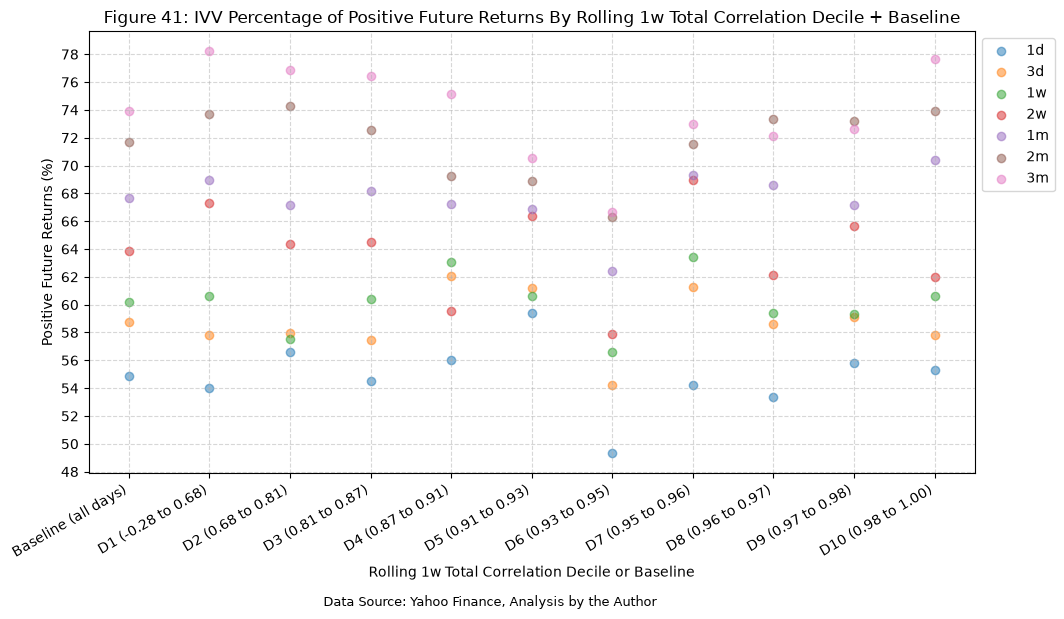

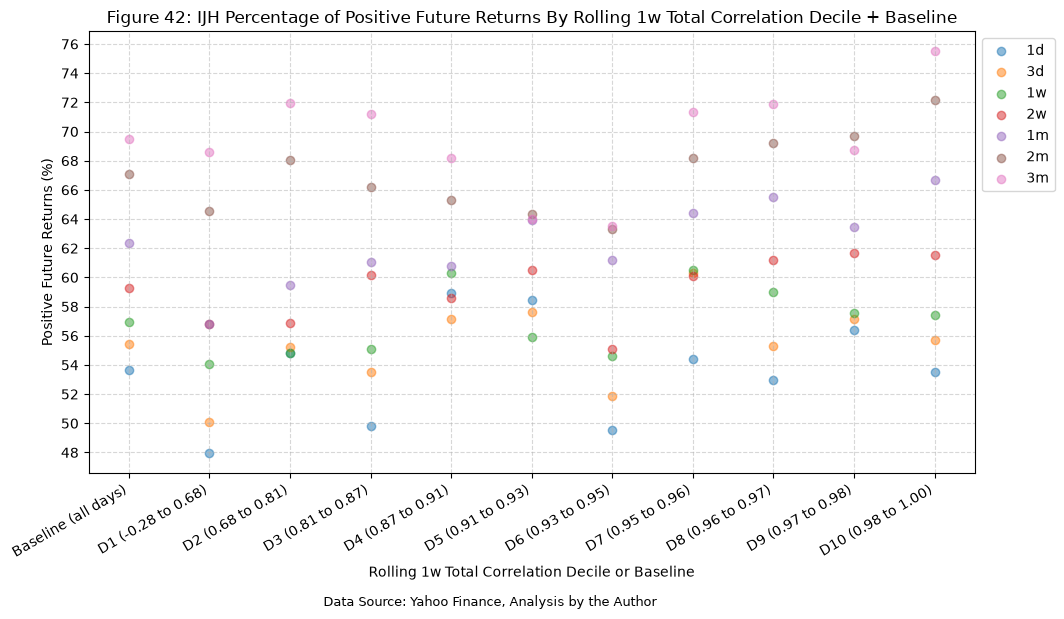

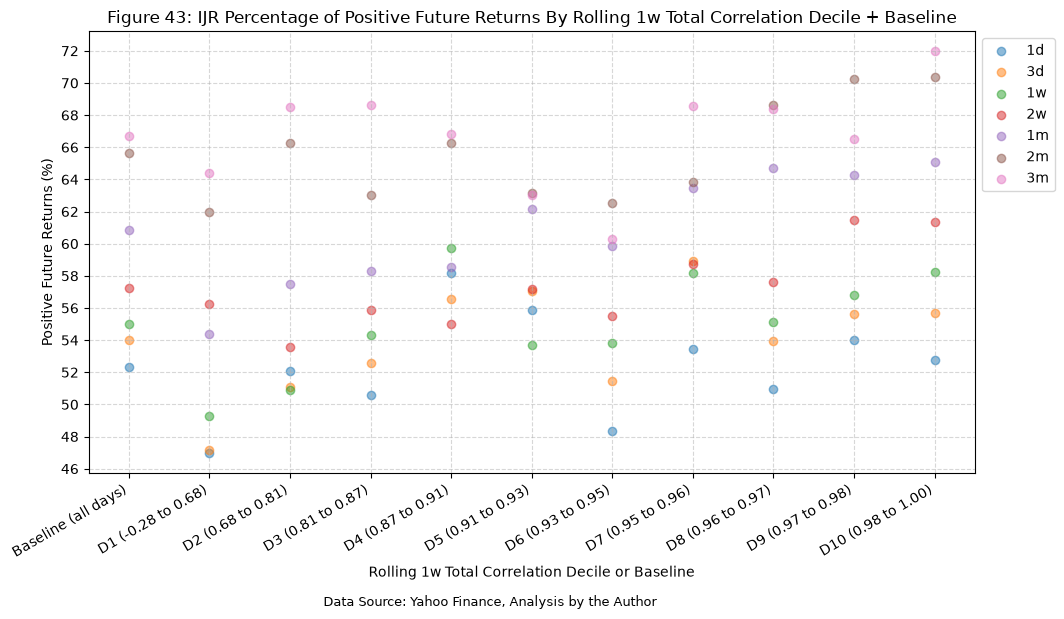

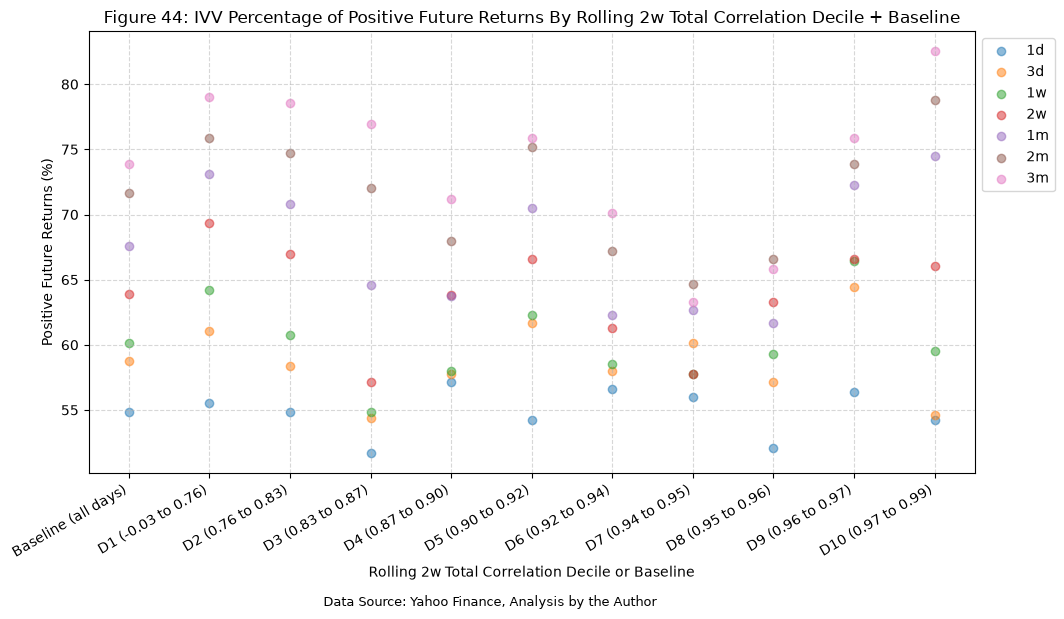

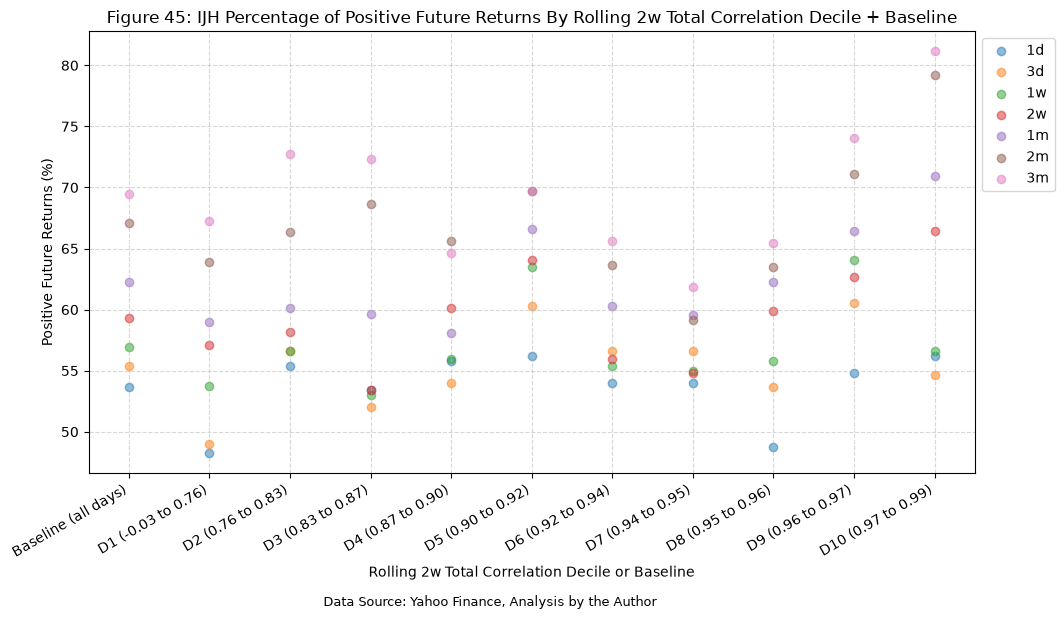

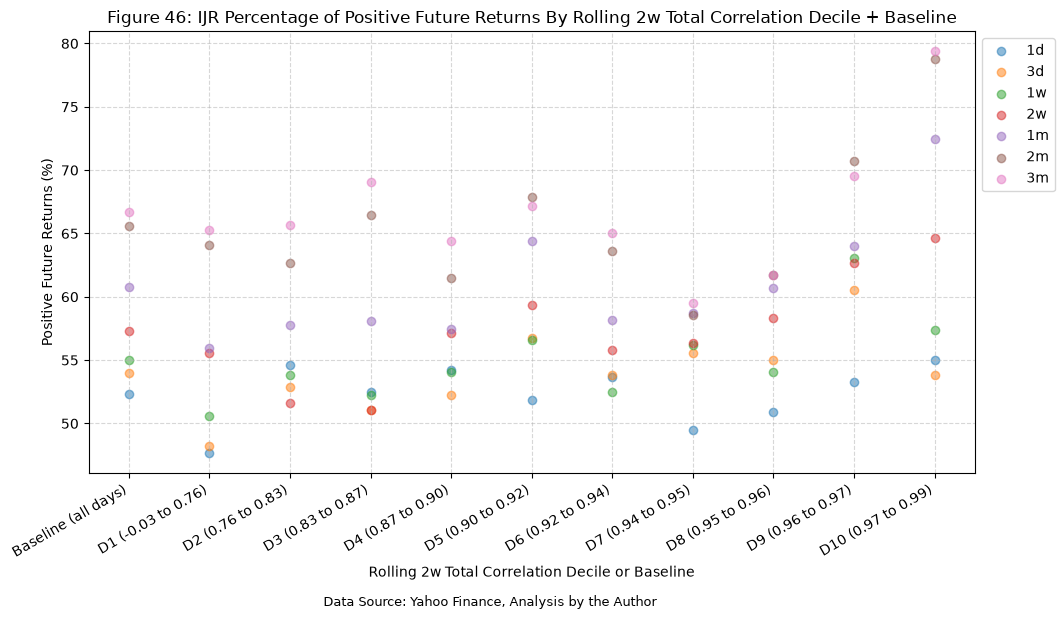

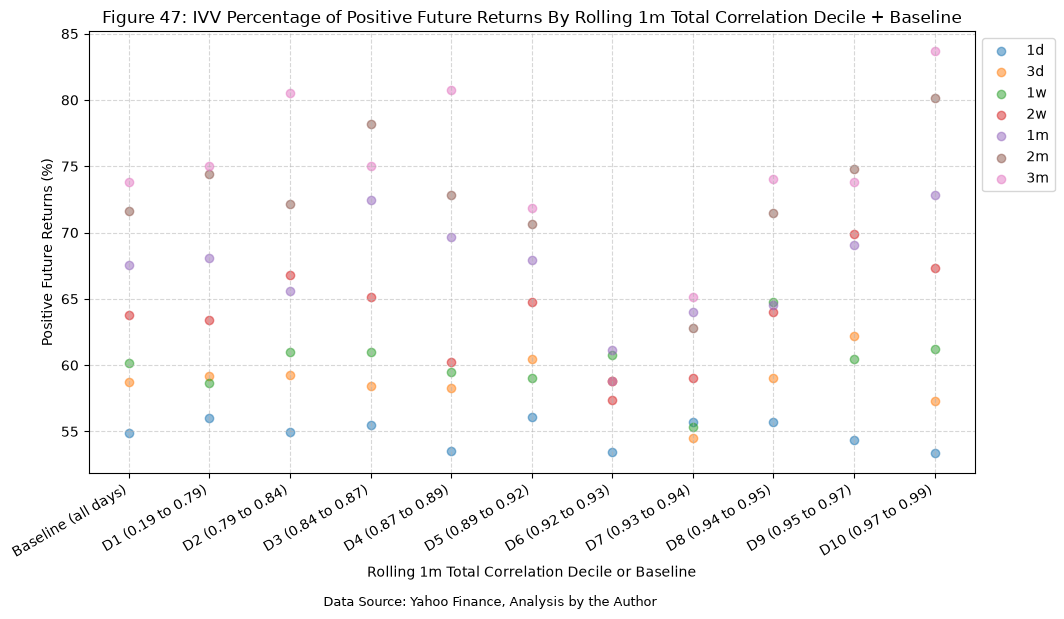

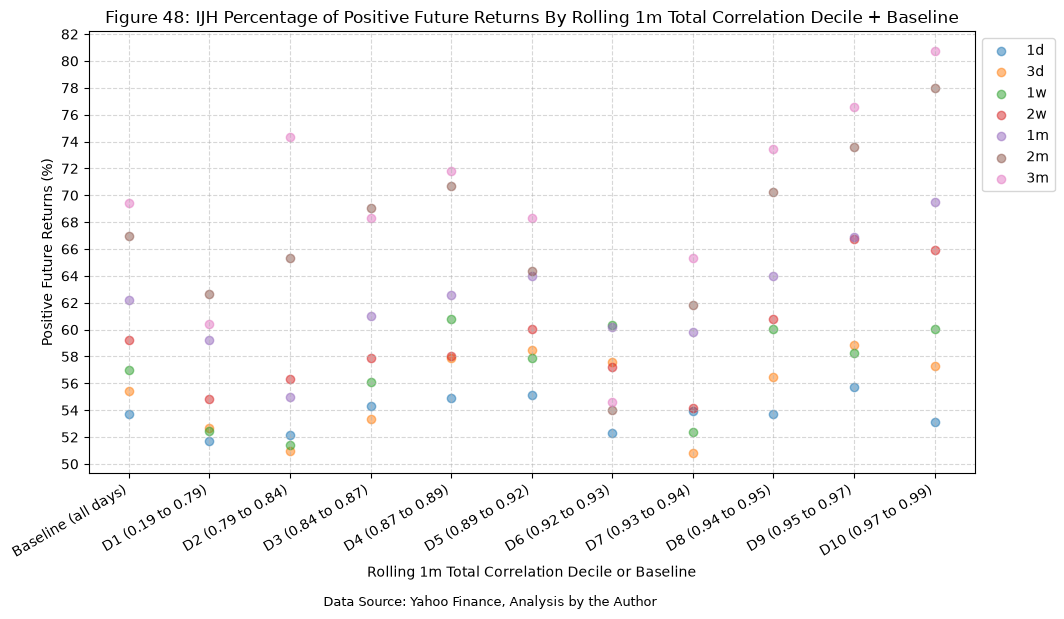

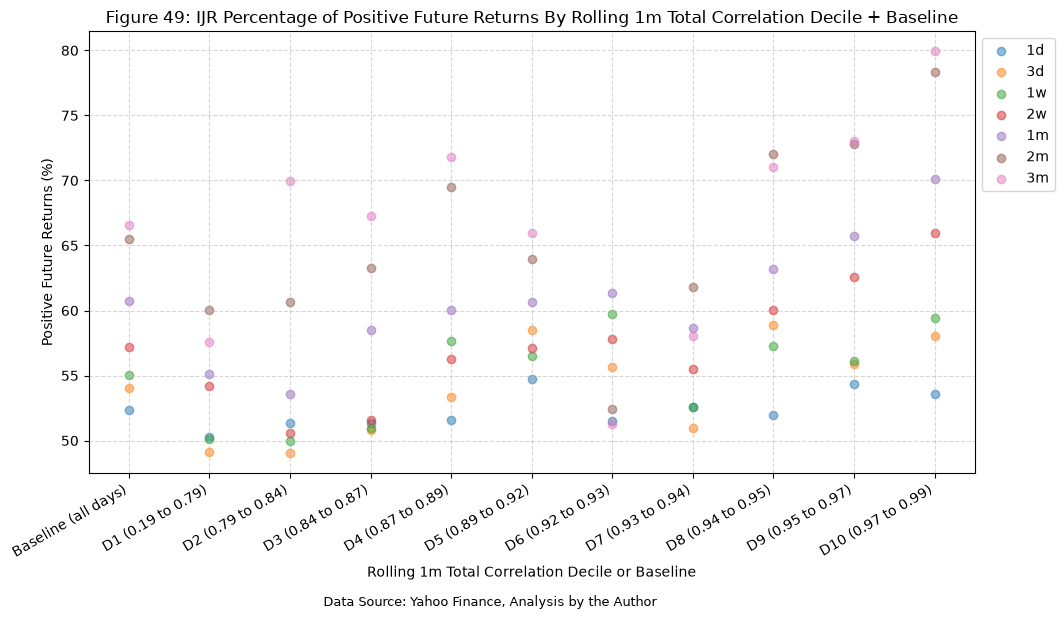

In [22]:
for window in analysis_windows:
    for ticker in tickers:
        # Select this fund's columns (one per return window) and move the decile labels into a column
        ticker_df = (
            decile_summary[window]["pct_positive"]
            .xs(ticker, axis=1, level=1)
            .reset_index(names="Decile")
        )

        plot_scatter(
            df=ticker_df,
            x_plot_column="Decile",
            y_plot_columns=list(return_windows.keys()),
            title=f"Figure {next(figure_number)}: {ticker} Percentage of Positive Future Returns By Rolling {window} Total Correlation Decile + Baseline",
            x_label=f"Rolling {window} Total Correlation Decile or Baseline",
            x_format="String",
            x_format_decimal_places="Auto",
            x_tick_spacing="Auto",
            x_tick_start=None,
            x_tick_rotation=30,
            y_label="Positive Future Returns (%)",
            y_format="Decimal",
            y_format_decimal_places=0,
            y_tick_spacing="Auto",
            y_tick_rotation=0,
            grid=True,
            legend=True,
            legend_location="upper left",
            legend_anchor=(1, 1),
            caption=f"Data Source: Yahoo Finance, Analysis by the Author",
        )

It's interesting what the baseline (all days) columns reveal about future returns. For *every* plot, the positive future return percentage increases as time increases. We see a similar, but slightly less pronounced, trend for the total rolling correlation deciles, and this suggests that, on average, the likelihood of positive future returns grows over longer time horizons, regardless of the rolling correlation decile. There is certainly a "belly" present in some of the plots, particularly at the 6th and 7th deciles.

The 10th decile consistently shows the highest positive future return percentages across all time horizons, indicating that assets in this decile tend to perform better in the future compared to those in lower deciles, so let's cherry pick the 2 week total rolling correlation for IVV, IJH, and IJR, at the 10th decile, and the 3 month forward return to examine more closely.

## 2w Total Rolling Correlation, 10th Decile, 3m Forward Return for IVV

In [23]:
# Assign each day to a correlation decile and record each decile's range
bucket = pd.qcut(total_rolling_corr_with_returns.dropna(subset=["total_rolling_correlation_2w"])["total_rolling_correlation_2w"], 10, labels=decile_labels)

# Merge the decile bucket back into the original DataFrame
total_rolling_corr_with_returns = total_rolling_corr_with_returns.dropna(subset=["total_rolling_correlation_2w"])
total_rolling_corr_with_returns["total_rolling_correlation_2w_decile"] = bucket

display(Markdown(f"Table {next(table_number)}: Total Rolling Correlations With 2w Decile Assignments"))
display(total_rolling_corr_with_returns)

Table 12: Total Rolling Correlations With 2w Decile Assignments

,IVV_IJH_3d,IVV_IJH_1w,IVV_IJH_2w,IVV_IJH_1m,IVV_IJH_3m,IVV_IJH_6m,IVV_IJH_1y,IVV_IJH_5y,IVV_IJH_10y,IVV_IJR_3d,...,IJH_Daily_Return_fwd_2m_CRR,IJR_Daily_Return_2m_CRR,IJR_Daily_Return_fwd_2m_CRR,IVV_Daily_Return_3m_CRR,IVV_Daily_Return_fwd_3m_CRR,IJH_Daily_Return_3m_CRR,IJH_Daily_Return_fwd_3m_CRR,IJR_Daily_Return_3m_CRR,IJR_Daily_Return_fwd_3m_CRR,total_rolling_correlation_2w_decile
Date,,,,,,,,,,,,,,,,,,,,,
2006-08-04,0.98,0.98,0.96,NaN,NaN,NaN,NaN,NaN,NaN,0.69,...,0.02,NaN,0.03,NaN,0.07,NaN,0.04,NaN,0.05,D7
2006-08-07,0.79,0.89,0.91,NaN,NaN,NaN,NaN,NaN,NaN,0.97,...,0.04,NaN,0.05,NaN,0.07,NaN,0.05,NaN,0.06,D4
2006-08-08,0.32,0.93,0.92,NaN,NaN,NaN,NaN,NaN,NaN,1.00,...,0.05,NaN,0.06,NaN,0.09,NaN,0.07,NaN,0.09,D5
2006-08-09,-0.01,0.80,0.93,NaN,NaN,NaN,NaN,NaN,NaN,0.74,...,0.06,NaN,0.07,NaN,0.10,NaN,0.09,NaN,0.10,D6
2006-08-10,0.99,0.89,0.95,NaN,NaN,NaN,NaN,NaN,NaN,0.96,...,0.06,NaN,0.07,NaN,0.09,NaN,0.09,NaN,0.10,D6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-22,0.90,0.87,0.87,0.75,0.79,0.78,0.80,0.88,0.90,-0.05,...,NaN,-0.05,NaN,0.04,NaN,-0.04,NaN,-0.04,NaN,D1
2026-10-23,0.98,0.83,0.86,0.76,0.80,0.78,0.80,0.88,0.90,-0.45,...,NaN,-0.05,NaN,0.03,NaN,-0.04,NaN,-0.05,NaN,D1
2026-10-26,0.98,0.91,0.89,0.78,0.80,0.78,0.80,0.88,0.90,0.07,...,NaN,-0.05,NaN,0.04,NaN,-0.04,NaN,-0.05,NaN,D2


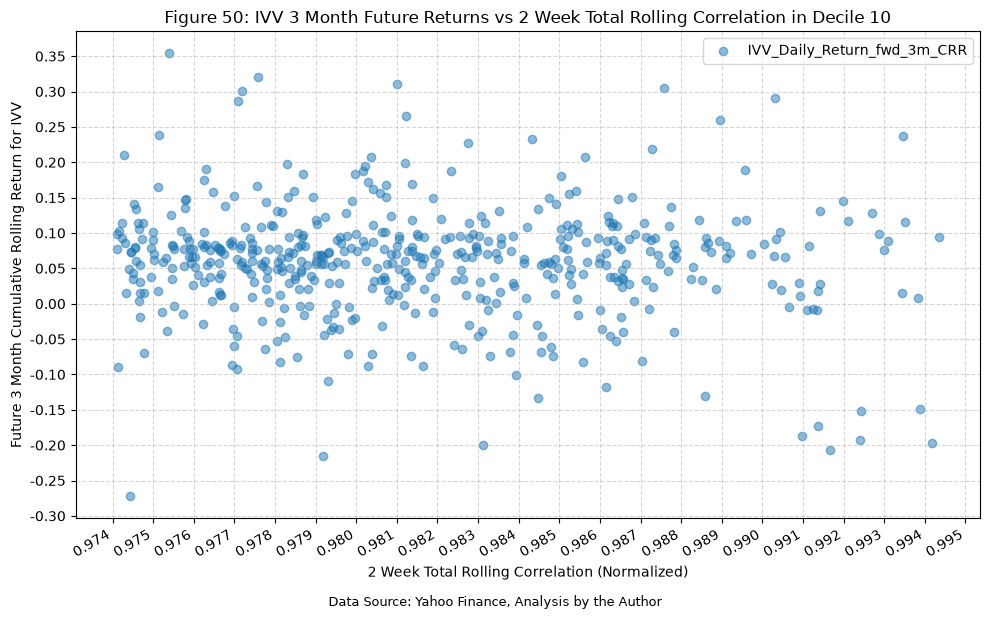

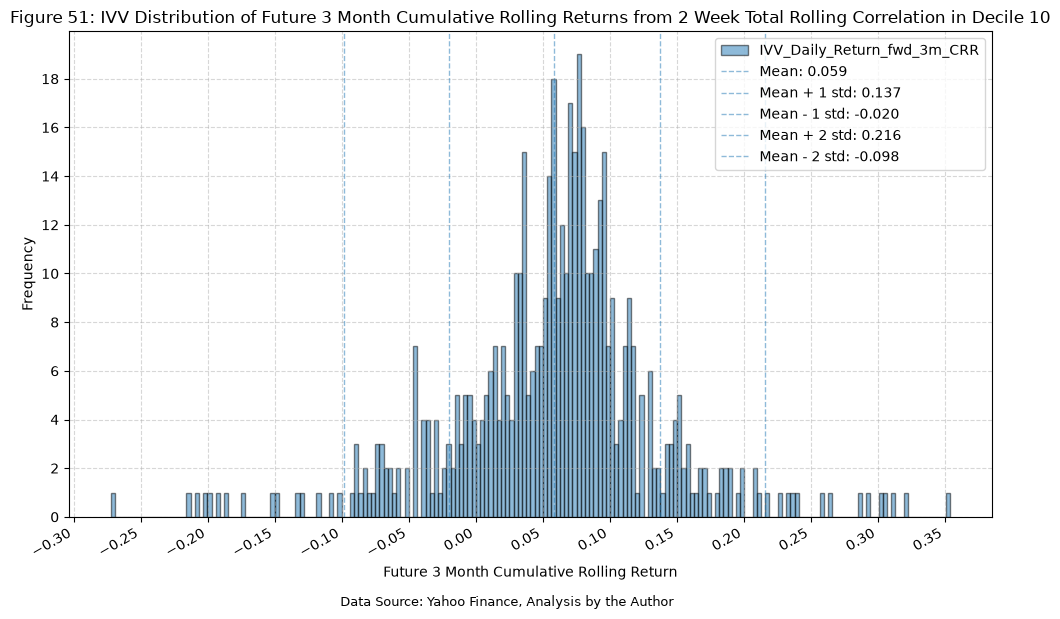

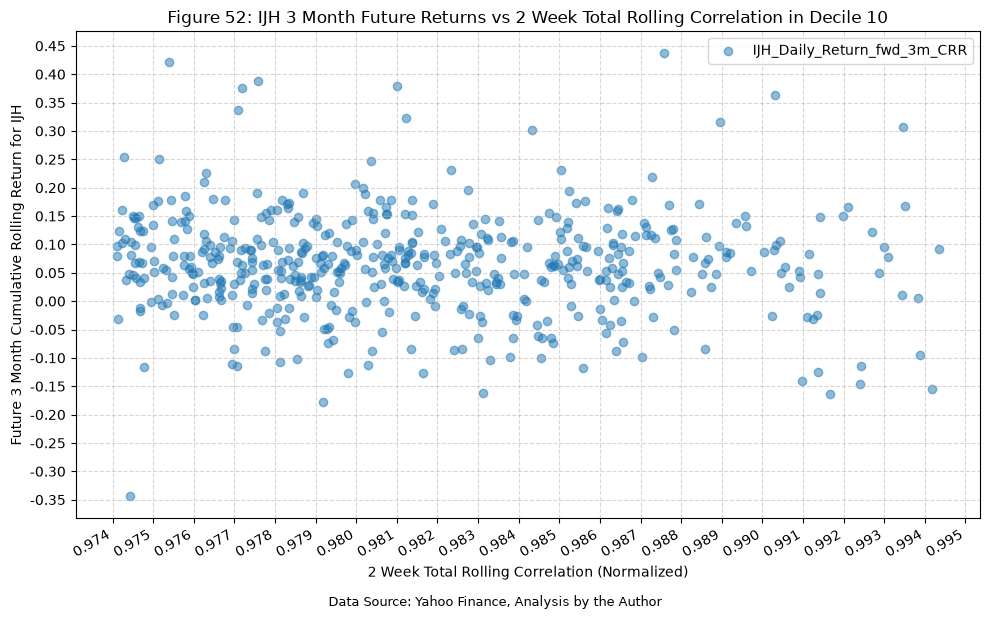

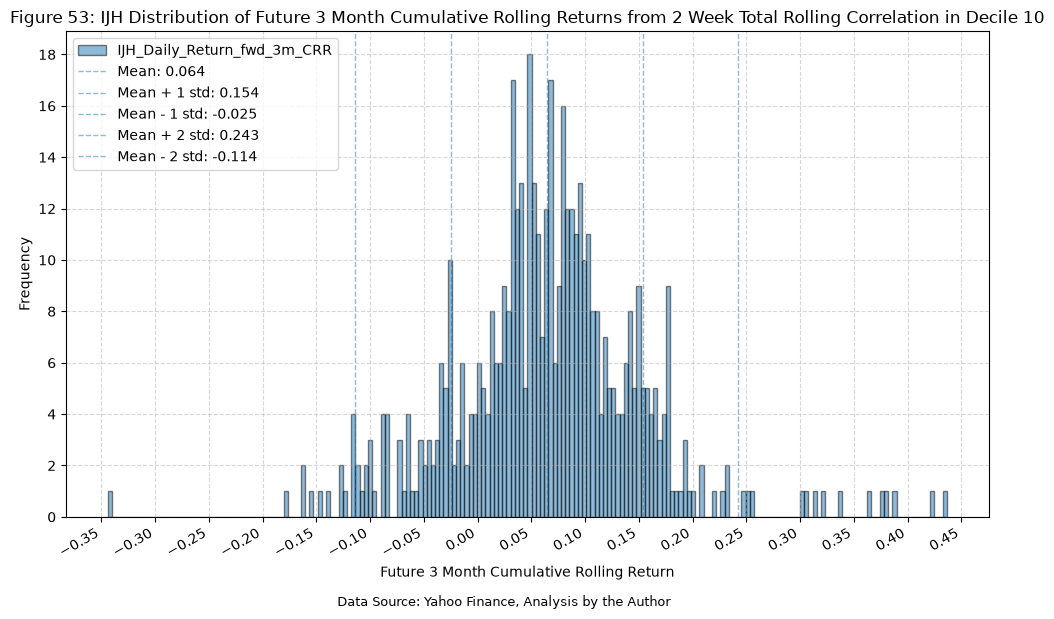

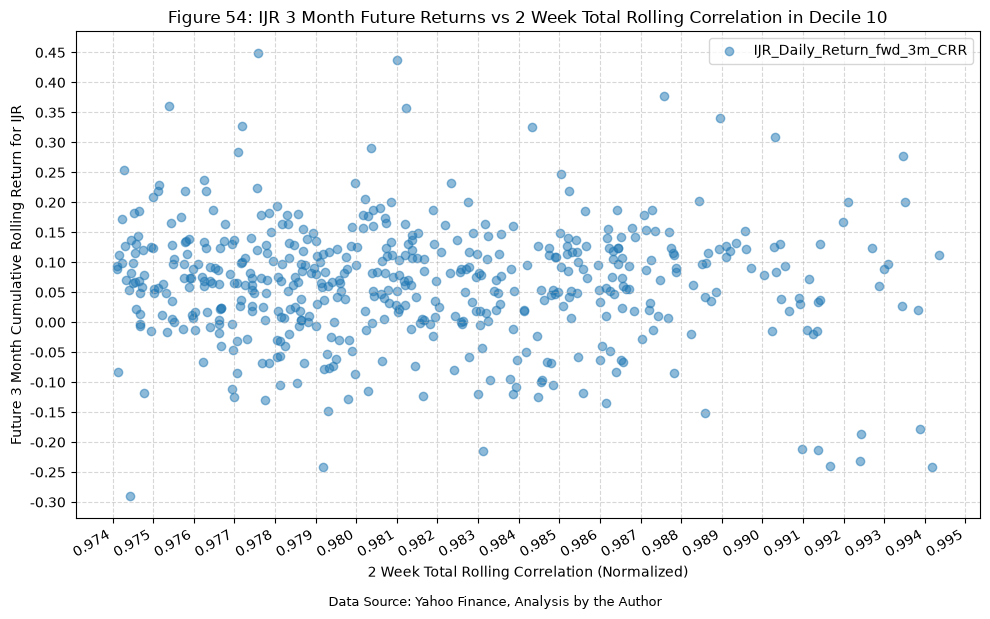

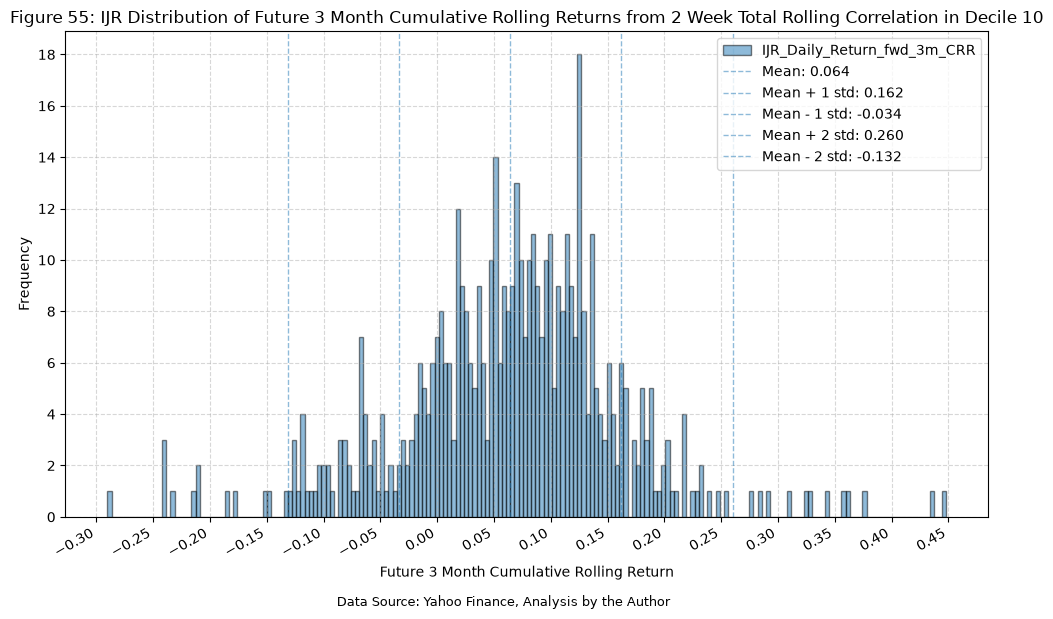

In [24]:
for ticker in tickers:
    plot_scatter(
        df=total_rolling_corr_with_returns[total_rolling_corr_with_returns["total_rolling_correlation_2w_decile"] == "D10"],
        x_plot_column="total_rolling_correlation_2w",
        y_plot_columns=[f"{ticker}_Daily_Return_fwd_3m_CRR"],
        title=f"Figure {next(figure_number)}: {ticker} 3 Month Future Returns vs 2 Week Total Rolling Correlation in Decile 10",
        x_label="2 Week Total Rolling Correlation (Normalized)",
        x_format="Decimal",
        x_format_decimal_places="Auto",
        x_tick_spacing="Auto",
        x_tick_start=None,
        x_tick_rotation=30,
        y_label=f"Future 3 Month Cumulative Rolling Return for {ticker}",
        y_format="Decimal",
        y_format_decimal_places=2,
        y_tick_spacing="Auto",
        y_tick_rotation=0,
        grid=True,
        legend=True,
        export_plot=False,
        plot_file_name=None,
        caption=f"Data Source: Yahoo Finance, Analysis by the Author",
    )

    plot_histogram(
        df=total_rolling_corr_with_returns[total_rolling_corr_with_returns["total_rolling_correlation_2w_decile"] == "D10"],
        plot_columns=[f"{ticker}_Daily_Return_fwd_3m_CRR"],
        title=f"Figure {next(figure_number)}: {ticker} Distribution of Future 3 Month Cumulative Rolling Returns from 2 Week Total Rolling Correlation in Decile 10",
        x_label="Future 3 Month Cumulative Rolling Return",
        x_tick_spacing="Auto",
        x_tick_rotation=30,
        y_label="Frequency",
        y_tick_spacing="Auto",
        y_tick_rotation=0,
        grid=True,
        legend=True,
        export_plot=False,
        plot_file_name=None,
        caption=f"Data Source: Yahoo Finance, Analysis by the Author",
    )

## Trading Strategy

Next, let's develop a simple trading strategy. When the total rolling correlation hits the 10th decile, we will open a long position in the fund, hold the position for exactly 3 months, and then close it. We'll run the strategy separately for each of the three funds. Here's the complete details:

* Use the 10th decile of the total rolling correlation as the signal for entering a trade.
* Position sizing: we always go fully long on the fund when a signal occurs, and we do not scale in or out.
* Entry: when the 2w total correlation decile is D10 on day i, buy the fund at that day's close.
* Exit: hold for exactly 63 trading days (return_windows["3m"]), then sell at that day's close.
* Overlapping signals: a D10 day that comes while a position is open is ignored. If the exit day is itself a D10 day, the strategy buys again, so the position just continues.
* Shared signal: the signal comes from the total correlation across all three funds, so the entry and exit dates are the same for IVV, IJH, and IJR. Only the returns differ.
* Settings: strategy_tickers, signal_decile and hold_days are variables at the top, so we can easily modify them to try other combinations.

We'll start with the strategy, and the complete list of trades.

In [25]:
# Strategy parameters
strategy_tickers = ["IVV", "IJH", "IJR"]
signal_column = "total_rolling_correlation_2w_decile"
signal_decile = "D10"
hold_days = return_windows["3m"]  # 63 trading days

strategy_df = total_rolling_corr_with_returns[
    ["total_rolling_correlation_2w", signal_column] + [f"{ticker}_Daily_Return" for ticker in strategy_tickers]
].copy()
for ticker in strategy_tickers:
    strategy_df[f"{ticker}_Daily_Return"] = strategy_df[f"{ticker}_Daily_Return"].fillna(0)
strategy_df["Signal"] = strategy_df[signal_column] == signal_decile

# Walk forward through the days. A signal at the close of day i opens a position at that close,
# which earns the returns of days i+1 through i+hold_days and is then closed. Signals that occur
# while a position is already open are ignored. The signal comes from the total correlation alone,
# so the entry and exit dates are the same for every fund and only the returns differ.
signals = strategy_df["Signal"].to_numpy()
position = np.zeros(len(strategy_df))
trades = []

i = 0
while i < len(strategy_df) - 1:  # A signal on the last day has no following days to trade
    if not signals[i]:
        i += 1
        continue

    entry_idx = i
    exit_idx = min(i + hold_days, len(strategy_df) - 1)
    position[entry_idx + 1 : exit_idx + 1] = 1

    trade = {
        "Entry Date": strategy_df.index[entry_idx],
        "Exit Date": strategy_df.index[exit_idx],
        "Entry Correlation": strategy_df["total_rolling_correlation_2w"].iloc[entry_idx],
        "Days Held": exit_idx - entry_idx,
        "Open": exit_idx - entry_idx < hold_days,  # True if the data ends before the hold period does
    }
    for ticker in strategy_tickers:
        daily_returns = strategy_df[f"{ticker}_Daily_Return"].to_numpy()
        trade[f"{ticker} Return"] = np.prod(1 + daily_returns[entry_idx + 1 : exit_idx + 1]) - 1
    trades.append(trade)

    i = exit_idx

strategy_df["Position"] = position
for ticker in strategy_tickers:
    strategy_df[f"{ticker}_Strategy_Return"] = strategy_df["Position"] * strategy_df[f"{ticker}_Daily_Return"]

display(Markdown(f"Table {next(table_number)}: Days in D10 With an Open Position"))
display(strategy_df[
    (strategy_df["total_rolling_correlation_2w_decile"] == "D10") &
    (strategy_df["Position"] == 1)
])

trades_df = pd.DataFrame(trades)
display(Markdown(f"Table {next(table_number)}: Strategy Trades"))
display(trades_df)

Table 13: Days in D10 With an Open Position

,total_rolling_correlation_2w,total_rolling_correlation_2w_decile,IVV_Daily_Return,IJH_Daily_Return,IJR_Daily_Return,Signal,Position,IVV_Strategy_Return,IJH_Strategy_Return,IJR_Strategy_Return
Date,,,,,,,,,,
2006-08-21,0.98,D10,-0.00,-0.01,-0.01,True,1.00,-0.00,-0.01,-0.01
2007-02-28,0.98,D10,0.01,0.01,0.01,True,1.00,0.01,0.01,0.01
2007-03-01,0.98,D10,-0.00,-0.00,-0.00,True,1.00,-0.00,-0.00,-0.00
2007-03-02,0.97,D10,-0.01,-0.02,-0.02,True,1.00,-0.01,-0.02,-0.02
2007-03-06,0.97,D10,0.02,0.02,0.02,True,1.00,0.02,0.02,0.02
...,...,...,...,...,...,...,...,...,...,...
2025-04-22,0.99,D10,0.03,0.03,0.02,True,1.00,0.03,0.03,0.02
2025-04-23,0.99,D10,0.02,0.01,0.01,True,1.00,0.02,0.01,0.01
2026-04-09,0.99,D10,0.01,0.00,0.01,True,1.00,0.01,0.00,0.01


Table 14: Strategy Trades

,Entry Date,Exit Date,Entry Correlation,Days Held,Open,IVV Return,IJH Return,IJR Return
0,2006-08-17,2006-11-15,0.98,63,False,0.08,0.08,0.10
1,2007-02-27,2007-05-29,0.98,63,False,0.10,0.09,0.08
2,2007-06-14,2007-09-13,0.98,63,False,-0.02,-0.05,-0.05
3,2007-09-27,2007-12-27,0.98,63,False,-0.03,-0.03,-0.07
4,2008-03-07,2008-06-06,0.98,63,False,0.06,0.15,0.11
5,2008-06-06,2008-09-05,0.99,63,False,-0.08,-0.10,-0.03
6,2008-11-14,2009-02-18,0.97,63,False,-0.09,-0.03,-0.08
7,2009-02-24,2009-05-26,0.98,63,False,0.19,0.23,0.23
8,2009-05-27,2009-08-25,0.98,63,False,0.16,0.18,0.19
9,2009-08-25,2009-11-23,0.99,63,False,0.08,0.05,0.03


Next, here's the statistics for win rate, average return, max gain, and max loss.

In [26]:
# Trade summary
closed_trades = trades_df[~trades_df["Open"]]

print(f"Total trades: {len(trades_df)} ({len(closed_trades)} closed)")
print(f"Time in market: {strategy_df['Position'].mean() * 100:.2f}%")

for ticker in strategy_tickers:
    trade_returns = closed_trades[f"{ticker} Return"]
    print(f"\n{ticker}:")
    print(f"  Win rate (closed trades): {(trade_returns > 0).mean() * 100:.2f}%")
    print(f"  Average return per closed trade: {trade_returns.mean() * 100:.2f}%")
    print(f"  Max trade gain: {trade_returns.max() * 100:.2f}%")
    print(f"  Max trade loss: {trade_returns.min() * 100:.2f}%")

Total trades: 44 (44 closed)
Time in market: 54.46%

IVV:
  Win rate (closed trades): 68.18%
  Average return per closed trade: 3.96%
  Max trade gain: 18.70%
  Max trade loss: -9.01%

IJH:
  Win rate (closed trades): 68.18%
  Average return per closed trade: 4.37%
  Max trade gain: 23.09%
  Max trade loss: -11.54%

IJR:
  Win rate (closed trades): 65.91%
  Average return per closed trade: 4.32%
  Max trade gain: 23.17%
  Max trade loss: -11.87%


Now we can compare the summary stats for the different funds and see how the strategy performed across IVV, IJH, and IJR.

In [27]:
# Compare each strategy against buy and hold for the same period
strategy_stats = pd.concat(
    [
        summary_stats(
            fund_list=[ticker],
            df=strategy_df[[return_column]],
            period="Daily",
            use_calendar_days=False,
            excel_export=False,
            pickle_export=False,
            output_confirmation=False,
        )
        for ticker in strategy_tickers
        for return_column in [f"{ticker}_Strategy_Return", f"{ticker}_Daily_Return"]
    ]
)

display(Markdown(f"Table {next(table_number)}: Strategy vs Buy and Hold Summary Statistics"))
display(strategy_stats)

Table 15: Strategy vs Buy and Hold Summary Statistics

,Number of Observations,Data Start Date,Data End Date,Annual Mean Return (Arithmetic),Annualized Volatility,Annualized Sharpe Ratio,CAGR (Geometric),Daily Max Return,Daily Max Return (Date),Daily Min Return,Daily Min Return (Date),Max Drawdown,Peak,Trough,Recovery Date,Calendar Days to Recovery,MAR Ratio
IVV_Strategy_Return,5090,2006-08-04,2026-10-28,0.09,0.15,0.60,0.08,0.10,2025-04-09,-0.12,2020-03-16,-0.30,2008-05-19,2009-03-09,2009-06-01,84,0.28
IVV_Daily_Return,5090,2006-08-04,2026-10-28,0.13,0.19,0.66,0.11,0.11,2008-10-28,-0.12,2020-03-16,-0.55,2007-10-09,2009-03-09,2012-08-16,1256,0.21
IJH_Strategy_Return,5090,2006-08-04,2026-10-28,0.10,0.18,0.58,0.09,0.11,2020-03-24,-0.14,2020-03-16,-0.36,2019-11-08,2020-03-23,2020-06-30,99,0.25
IJH_Daily_Return,5090,2006-08-04,2026-10-28,0.12,0.22,0.53,0.10,0.11,2020-03-24,-0.14,2020-03-16,-0.55,2007-06-04,2009-03-09,2010-12-02,633,0.18
IJR_Strategy_Return,5090,2006-08-04,2026-10-28,0.10,0.19,0.54,0.09,0.09,2025-04-09,-0.12,2020-03-16,-0.35,2019-11-05,2020-03-23,2020-07-21,120,0.25
IJR_Daily_Return,5090,2006-08-04,2026-10-28,0.12,0.24,0.50,0.09,0.09,2025-04-09,-0.12,2020-03-16,-0.58,2007-07-19,2009-03-09,2011-02-07,700,0.16


And finally, the plots for the cumulative returns and drawdowns.

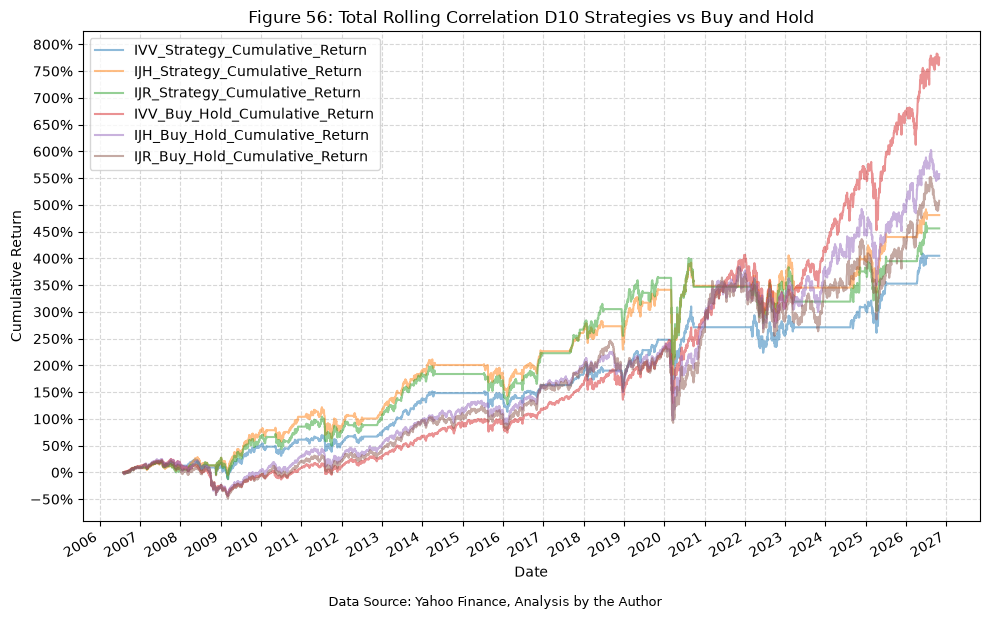

In [28]:
# Cumulative returns for each strategy and buy and hold
for ticker in strategy_tickers:
    strategy_df[f"{ticker}_Strategy_Cumulative_Return"] = (1 + strategy_df[f"{ticker}_Strategy_Return"]).cumprod() - 1
    strategy_df[f"{ticker}_Buy_Hold_Cumulative_Return"] = (1 + strategy_df[f"{ticker}_Daily_Return"]).cumprod() - 1

plot_time_series(
    df=strategy_df,
    plot_start_date=None,
    plot_end_date=None,
    plot_columns=[f"{ticker}_Strategy_Cumulative_Return" for ticker in strategy_tickers]
    + [f"{ticker}_Buy_Hold_Cumulative_Return" for ticker in strategy_tickers],
    title=f"Figure {next(figure_number)}: Total Rolling Correlation {signal_decile} Strategies vs Buy and Hold",
    x_label="Date",
    x_format="Year",
    x_tick_spacing=1,
    x_tick_start=None,
    x_tick_rotation=30,
    y_label="Cumulative Return",
    y_format="Percentage",
    y_format_decimal_places=0,
    y_tick_spacing="Auto",
    y_tick_rotation=0,
    grid=True,
    legend=True,
    export_plot=False,
    plot_file_name=None,
    caption=f"Data Source: Yahoo Finance, Analysis by the Author",
)

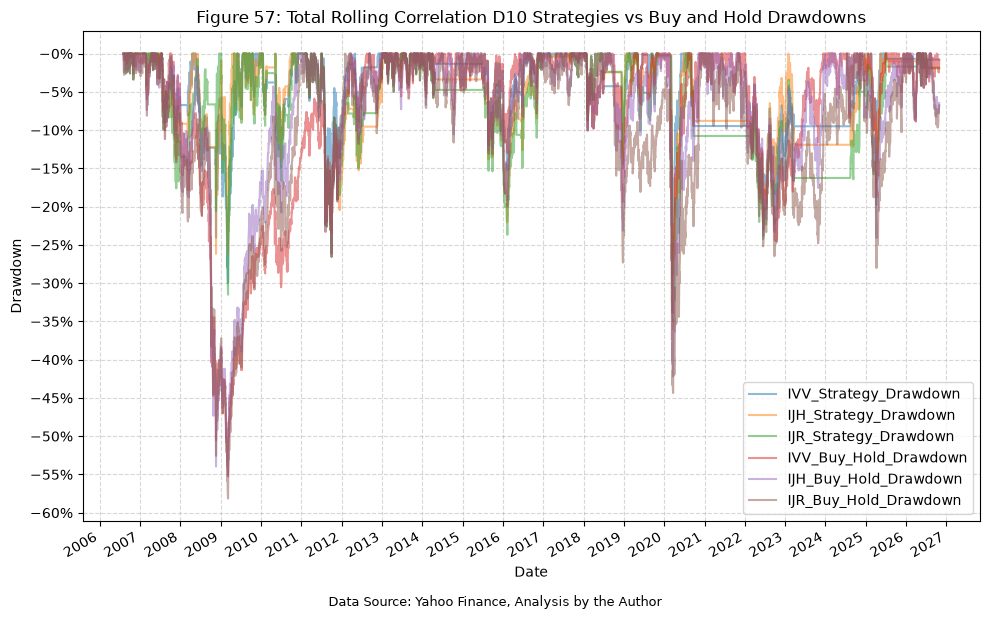

In [29]:
# Drawdowns for each strategy and buy and hold, measured from the running peak of each equity curve
for ticker in strategy_tickers:
    strategy_equity = (1 + strategy_df[f"{ticker}_Strategy_Return"]).cumprod()
    buy_hold_equity = (1 + strategy_df[f"{ticker}_Daily_Return"]).cumprod()

    strategy_df[f"{ticker}_Strategy_Drawdown"] = strategy_equity / strategy_equity.cummax() - 1
    strategy_df[f"{ticker}_Buy_Hold_Drawdown"] = buy_hold_equity / buy_hold_equity.cummax() - 1

plot_time_series(
    df=strategy_df,
    plot_start_date=None,
    plot_end_date=None,
    plot_columns=[f"{ticker}_Strategy_Drawdown" for ticker in strategy_tickers]
    + [f"{ticker}_Buy_Hold_Drawdown" for ticker in strategy_tickers],
    title=f"Figure {next(figure_number)}: Total Rolling Correlation {signal_decile} Strategies vs Buy and Hold Drawdowns",
    x_label="Date",
    x_format="Year",
    x_tick_spacing=1,
    x_tick_start=None,
    x_tick_rotation=30,
    y_label="Drawdown",
    y_format="Percentage",
    y_format_decimal_places=0,
    y_tick_spacing="Auto",
    y_tick_rotation=0,
    grid=True,
    legend=True,
    export_plot=False,
    plot_file_name=None,
    caption=f"Data Source: Yahoo Finance, Analysis by the Author",
)

We end up with 44 trades over the 20 year period, with a win rate of 68% for IVV and IJH, and 66% for IJR, not bad overall. Since the signal is shared, all three strategies spend just under 55% of their time in the market, which really gives us an opportunity to use our capital the other 45% of the time, either in a risk free asset or another strategy altogether.

For IVV, with a CAGR of 8%, we underperform the buy-and-hold strategy over the same period, but we also experience lower volatility (16% vs 19%), and much lower max drawdowns (30% vs 55%). Our strategy gives us a MAR ratio of 0.28, vs 0.20 for the buy-and-hold strategy.

IJH and IJR tell a similar story, but the gap in CAGR is much smaller:

* IJH: a CAGR of 9.1% vs 9.7% for buy-and-hold, with lower volatility (18% vs 22%), lower max drawdowns (36% vs 55%), and a MAR ratio of 0.25 vs 0.18.
* IJR: a CAGR of 8.9% vs 9.3% for buy-and-hold, with lower volatility (19% vs 24%), lower max drawdowns (35% vs 58%), and a MAR ratio of 0.25 vs 0.16.

For IJH and IJR, we give up less than 1% of CAGR per year in exchange for the reduced risk, and both strategies also have a higher Sharpe ratio than their buy-and-hold counterparts, which is not the case for IVV.

The difference in CAGR does add up over the long term, the effect of which we can see in the cumulative return plot, particularly for IVV.

The drawdown plot further illustrates the reduced risk of the strategies compared to the buy-and-hold approach, highlighting the lower maximum drawdowns experienced over the same period. During the GFC, the IVV strategy experienced its max drawdown of 30%, which was significantly lower than that of the buy-and-hold strategy at 55%. Interestingly, the max drawdowns for the IJH and IJR strategies came during the COVID crash in early 2020 rather than the GFC, while all three buy-and-hold strategies saw their max drawdowns during the GFC.

## Conclusion

Overall, this was a brief but interesting study that dove into the historical correlations amongst a wide range of asset classes. We looked at a series of rolling correlations amongst the asset classes, and then delved into the different deciles of a "total correlation" metric, assembled from the rolling correlations of 3 well known US equity ETFs. This analysis, including comparison to a baseline, gave us insight into where the total correlations could be used to improve our ability to time market entries and exits. Finally, we built a simple trading strategy using a single total correlation window and decile and a single future return window, as a proof of concept for how these insights could be applied in practice. This strategy, while underperforming over the long-term, did have lower volatility and drawdowns, demonstrating the potential risk management benefits of incorporating total correlation information into trading decisions.

## Future Investigation

None

## References

None